# Orbits and observability — ACME hands-on session

**Gran Sasso Science Institute — ACME Centre of Expertise**

For a space-based detector the orbit decides *what* can be observed and *under which
conditions*. In this notebook we start from a handful of orbital elements and work our
way to the quantities a payload team actually cares about:

| Section | Question |
|---|---|
| 1–4 | Where is the satellite? (elements → propagation → 3D orbit → ground track) |
| 5 | When is it in **eclipse**, and how does the **beta angle** drive it? |
| 6 | How does an orbit become a **sky**? (orbit → ECI → equatorial → galactic → Mollweide) |
| 7 | Which part of the sky does an all-sky detector **observe**, and for how long? |
| 8 | When is a given source — the **Crab Nebula** — visible, and when is it **occulted** by the Earth? |
| 9 | What changes when the **J2** perturbation is switched on in the sky sections? |


> **Physics scope.** We use a *circular orbit with the secular J2 drifts* (rotation of the
> orbital plane and change of the along-track rate) and a *spherical Earth*: J2 enters only
> the gravity field, while the geometry (ground track, shadow, horizon, occultation) uses a
> sphere of radius $R_\oplus$. J2 is on by
> default in sections 1–5 (`USE_J2`); sections 6–8 look at the sky on the Keplerian orbits
> and section 9 switches J2 on again. 

**How to use.** Run the cells from top to bottom (about 2–3 minutes in total). The knobs you
may want to change: `USE_J2` and the mission dates (1.1), `N_ORBITS_3D` (3), `FOV_DEG` and
`H_ATM_KM` (7), `ORB_8` and `TARGET` (8), `DAY_9` (9), `FIG_DPI` (setup).


## 0. Setup

Run this cell first. It imports everything and fixes the physical constants used
throughout the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import time
from dataclasses import dataclass, field, replace
from datetime import datetime, timedelta
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display

FIG_DPI = 96                # size of ALL figures on screen: e.g. 120 = 25 % larger

mpl.rcParams.update({
    "figure.dpi": FIG_DPI, "savefig.dpi": 120, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10, "legend.fontsize": 9,
})

ASSETS = Path("assets")
OUTPUT = Path("output"); OUTPUT.mkdir(exist_ok=True)

# ---------------------------------------------------------------- constants
R_EARTH   = 6378.137        # Earth equatorial radius                  [km]
MU_EARTH  = 398600.4418     # Earth gravitational parameter        [km^3/s^2]
J2        = 1.08262668e-3   # Earth second zonal harmonic               [-]
OBLIQUITY = 23.43929111     # obliquity of the ecliptic at J2000       [deg]
OMEGA_E   = 7.2921150e-5    # Earth rotation rate                    [rad/s]
DAY       = 86400.0         # seconds in a day                          [s]

print(f"R_Earth = {R_EARTH} km | mu = {MU_EARTH} km^3/s^2 | J2 = {J2:.6e}")
_sid = 2*np.pi/OMEGA_E                                    # sidereal day [s]
print(f"Earth rotation period = {_sid/3600:.4f} h = {int(_sid//3600)} h {int(_sid%3600//60)} m "
      f"{_sid%60:.1f} s  (sidereal day)")


R_Earth = 6378.137 km | mu = 398600.4418 km^3/s^2 | J2 = 1.082627e-03
Earth rotation period = 23.9345 h = 23 h 56 m 4.1 s  (sidereal day)


### 0.1 Time

Two time quantities are needed everywhere:

* the **Julian date**, from which both the GMST and the Sun direction are computed;
* the **Greenwich Mean Sidereal Time (GMST)**, the angle between the Greenwich meridian
  and the vernal equinox — this is what turns an inertial position into a longitude.

> All dates in this notebook are **UTC**, written as plain (timezone-free) `datetime`
> objects: `datetime(year, month, day, hour, minute)`. Local time would shift the ground
> track by 15° per hour. (Strictly, GMST needs UT1, not UTC: they differ by less than
> 0.9 s, i.e. less than 0.004°.)

Note the Earth rotates once per *sidereal* day (86164 s), not per solar day. Forgetting
this is the single most common bug in a ground-track script: the two differ by 0.9856° per
day, so after one month the track is off by ~30° (2 h of rotation), after one year by a full
turn.

In [2]:
def julian_date(dt: datetime) -> float:
    '''Julian date of a UTC datetime (Meeus).'''
    y, m = dt.year, dt.month
    d = dt.day + (dt.hour + dt.minute/60 + (dt.second + dt.microsecond*1e-6)/3600) / 24
    if m <= 2:
        y, m = y - 1, m + 12
    A = y // 100
    B = 2 - A + A // 4
    return int(365.25*(y + 4716)) + int(30.6001*(m + 1)) + d + B - 1524.5


def gmst_rad(dt: datetime) -> float:
    '''Greenwich Mean Sidereal Time [rad] at a UTC datetime (IAU 1982).'''
    T = (julian_date(dt) - 2451545.0) / 36525.0
    s = (67310.54841 + (876600*3600 + 8640184.812866)*T
         + 0.093104*T**2 - 6.2e-6*T**3)          # seconds of time
    return np.radians((s % 86400.0) / 240.0)     # 240 s of time = 1 degree


def sun_unit_eci(dt):
    '''Unit vector to the Sun in ECI (equatorial mean-of-date), accuracy ~0.01 deg.

    Obliquity of date: eps = OBLIQUITY - 0.0130042 T (T in Julian centuries).

    Two kinds of input:
      * one datetime                      -> one vector, shape (3,)
      * an array of N times, in Julian centuries since J2000
        T = (JD - 2451545.0)/36525 (see `jcent`, section 5) -> N vectors, shape (N, 3)
    The second form computes the Sun for a whole mission in one call.
    '''
    T = (julian_date(dt) - 2451545.0)/36525.0 if isinstance(dt, datetime) else np.asarray(dt)
    L = (280.460 + 36000.771*T) % 360.0                       # mean longitude
    M = np.radians((357.5291092 + 35999.05034*T) % 360.0)     # mean anomaly
    lam = np.radians(L + 1.914666471*np.sin(M) + 0.019994643*np.sin(2*M))
    eps = np.radians(OBLIQUITY - 0.0130042*T)                 # obliquity of date
    return np.stack([np.cos(lam),
                     np.cos(eps)*np.sin(lam),
                     np.sin(eps)*np.sin(lam)], axis=-1)


# Official 2030 equinoxes and solstices, UTC 
SEASONS_2030 = [("March equinox",     datetime(2030,  3, 20, 13, 51),   0.0),
                ("June solstice",     datetime(2030,  6, 21,  7, 31),  90.0),
                ("September equinox", datetime(2030,  9, 22, 23, 27), 180.0),
                ("December solstice", datetime(2030, 12, 21, 20,  9), 270.0)]

for name, when, lam_deg in SEASONS_2030:
    s   = sun_unit_eci(when)
    eps = np.radians(OBLIQUITY - 0.0130042*(julian_date(when) - 2451545.0)/36525.0)
    lam = np.radians(lam_deg)
    expected = np.array([np.cos(lam), np.cos(eps)*np.sin(lam), np.sin(eps)*np.sin(lam)])
    err = np.degrees(np.arccos(np.clip(s @ expected, -1, 1)))*3600
    ra  = np.degrees(np.arctan2(s[1], s[0])) % 360
    dec = np.degrees(np.arcsin(s[2]))
    print(f"{name:18s} {when:%Y-%m-%d %H:%M} UTC   RA = {ra:8.4f}  Dec = {dec:+8.4f} deg"
          f"   error = {err:4.1f} arcsec")
print(f"\nJulian date of 2030-01-01 00:00 UTC = {julian_date(datetime(2030, 1, 1)):.1f}")
print(f"GMST at 2030-01-01 00:00 UTC = {np.degrees(gmst_rad(datetime(2030, 1, 1))):.3f} deg")


March equinox      2030-03-20 13:51 UTC   RA = 359.9977  Dec =  -0.0010 deg   error =  9.0 arcsec
June solstice      2030-06-21 07:31 UTC   RA =  89.9963  Dec = +23.4353 deg   error = 12.1 arcsec
September equinox  2030-09-22 23:27 UTC   RA = 179.9977  Dec =  +0.0010 deg   error =  8.8 arcsec
December solstice  2030-12-21 20:09 UTC   RA = 269.9975  Dec = -23.4353 deg   error =  8.3 arcsec

Julian date of 2030-01-01 00:00 UTC = 2462502.5
GMST at 2030-01-01 00:00 UTC = 100.692 deg


## 1. Defining an orbit

A circular orbit is fully specified by five numbers plus an epoch:

| element | symbol | meaning |
|---|---|---|
| semi-major axis | $a$ | orbit size — here $a = R_\oplus + h$ |
| eccentricity | $e$ | $=0$ for all orbits in this notebook |
| inclination | $i$ | tilt of the orbital plane w.r.t. the equator |
| RAAN | $\Omega$ | angle from the vernal equinox (ECI $x$ axis) to the ascending node, measured eastward along the equator |
| argument of latitude | $u$ | where the satellite is along the orbit, measured from the ascending node in the direction of motion |

For a circular orbit the perigee is undefined, so the usual argument of perigee $\omega$
and true anomaly $\nu$ merge into $u = \omega + \nu$ (NUSES sheet: $0° + 0° = 0°$).

**Derived quantities.** Mean motion, speed and the J2 drift of the node:

$$ n=\sqrt{\frac{\mu}{a^{3}}},\qquad v=\sqrt{\frac{\mu}{a}},\qquad
   \dot\Omega = -\frac{3}{2}J_2\left(\frac{R_\oplus}{a}\right)^{2} n\cos i $$

The nodal drift is what makes sun-synchronous orbits possible ($\dot\Omega = +0.9856^\circ$/day,
one turn per year).

**Two periods.**

* **Keplerian period** — one revolution in the two-body problem (point-mass Earth):
  $T_k = 2\pi/n = 2\pi\sqrt{a^3/\mu}$.
* **Nodal period** — the time between two successive ascending-node crossings. J2 also
  changes the rate at which the satellite runs along its orbit (first-order secular theory,
  $e=0$, $u=\omega+\nu$):

$$ \dot u = n\left[1 + \frac{3}{4}J_2\left(\frac{R_\oplus}{a}\right)^{2}\left(8\cos^2 i - 2\right)\right],
   \qquad T_n = \frac{2\pi}{\dot u} \simeq T_k\left[1 - \frac{3}{2}J_2\left(\frac{R_\oplus}{a}\right)^{2}\left(4\cos^2 i - 1\right)\right]$$

  $T_n < T_k$ for $i < 60°$, $T_n > T_k$ for $60° < i < 120°$. The difference is 4 to 12
  seconds per orbit for our three missions (CE −12.2 s, NUSES +7.4 s, ISS −4.3 s), but it accumulates: after a month, event times computed with $T_k$
  would be off by up to ~1.5 h.

**This notebook propagates with $\dot u$, so the period used everywhere is $T_n$.**

**Perturbations.** A real orbit is not a fixed Keplerian ellipse: the Earth's oblateness
(J2 and higher harmonics), atmospheric drag, the Sun and the Moon and radiation pressure
all perturb it. For simplicity we keep only the largest secular effect for a low orbit,
**J2**: it turns the orbital plane ($\dot\Omega$) and changes the along-track rate
($\dot u$). `USE_J2` in the parameters block (section 1.1) switches it on (default) or
off: sections 1–5 follow that choice.


In [3]:
@dataclass
class Orbit:
    '''Template of a circular orbit. The actual missions are created in section 1.1.'''
    name: str
    altitude_km: float          # circular altitude                               [km]
    inc_deg: float              # inclination                                     [deg]
    start: datetime             # mission start, UTC  (= epoch, t = 0)
    end: datetime               # mission end, UTC
    raan_deg: float = 0.0       # RAAN at epoch                                   [deg]
    u0_deg: float = 0.0         # argument of latitude at epoch, u = omega + nu   [deg]
    color: str = "tab:blue"     # colour used in the plots
    use_j2: bool = True         # False -> Keplerian orbit, no J2 drifts
    tag: str = ""               # short key ("CE", "NUSES", "ISS"): FOV_DEG, file names
    # ecc: float = 0.0          # eccentricity: not used, every orbit here is circular

    # ---- derived quantities (filled in __post_init__) ----
    a: float = field(init=False)              # semi-major axis                 [km]
    n: float = field(init=False)              # Keplerian mean motion           [rad/s]
    u_dot: float = field(init=False)          # rate of u, with J2              [rad/s]
    raan_dot: float = field(init=False)       # nodal drift, J2                 [rad/s]
    period_kep_s: float = field(init=False)   # Keplerian period Tk             [s]
    period_s: float = field(init=False)       # nodal period Tn, USED EVERYWHERE [s]
    v_kms: float = field(init=False)          # orbital speed                   [km/s]

    def __post_init__(self):
        self.a = R_EARTH + self.altitude_km
        self.n = np.sqrt(MU_EARTH / self.a**3)
        k = J2 * (R_EARTH/self.a)**2 if self.use_j2 else 0.0
        c = np.cos(np.radians(self.inc_deg))
        self.raan_dot     = -1.5 * k * self.n * c
        self.u_dot        = self.n * (1.0 + 0.75 * k * (8*c**2 - 2))
        self.period_kep_s = 2*np.pi / self.n
        self.period_s     = 2*np.pi / self.u_dot
        self.v_kms        = np.sqrt(MU_EARTH / self.a)

    # ---- handy properties ----
    @property
    def epoch(self):            return self.start
    @property
    def duration_days(self):    return (self.end - self.start).total_seconds() / DAY
    @property
    def orbits_per_day(self):   return DAY / self.period_s
    @property
    def raan_dot_deg_day(self): return np.degrees(self.raan_dot) * DAY
    @property
    def max_latitude_deg(self): return min(self.inc_deg, 180 - self.inc_deg)
    @property
    def is_sso(self):
        # sun-synchronous if the node follows the Sun (360 deg / 365.2422 d = 0.9856 deg/day)
        # within 0.02 deg/day, i.e. ~2 % of the target rate
        return abs(self.raan_dot_deg_day - 360/365.2422) < 0.02

    def summary(self):
        return (f"{self.name}\n"
                f"  mission               {self.start:%Y-%m-%d %H:%M} -> {self.end:%Y-%m-%d %H:%M} UTC"
                f"  ({self.duration_days:.0f} days)\n"
                f"  altitude                {self.altitude_km:8.2f} km\n"
                f"  semi-major axis  a  = {self.a:8.2f} km\n"
                f"  inclination      i  = {self.inc_deg:8.2f} deg   "
                f"(|lat| <= {self.max_latitude_deg:.2f} deg)\n"
                f"  RAAN             W  = {self.raan_deg:8.2f} deg\n"
                f"  mean motion      n  = {self.n:.4e} rad/s   (Keplerian)\n"
                f"  period, Keplerian Tk= {self.period_kep_s/60:8.3f} min  "
                f"({DAY/self.period_kep_s:.3f} orbits/day)\n"
                f"  period, nodal    Tn = {self.period_s/60:8.3f} min  "
                f"({self.orbits_per_day:.3f} orbits/day)  <-- used by the propagator\n"
                f"                        Tn - Tk = {self.period_s - self.period_kep_s:+.2f} s per orbit\n"
                f"  orbital speed    v  = {self.v_kms:8.3f} km/s\n"
                f"  nodal drift      W' = {self.raan_dot_deg_day:+8.4f} deg/day"
                f"{'   --> SUN-SYNCHRONOUS' if self.is_sso else ''}")

### 1.1 The three missions

**Crystal Eye** — an all-sky X/gamma-ray monitor for multi-messenger follow-up, at
550 km and $i = 37°$, assumed launch from Kourou.

**NUSES** — a GSSI-led technology-demonstrator mission carrying the *Zirè* and *Terzina*
instruments on the NIMBUS platform, in a **sun-synchronous** orbit.

**ISS** — its dates are illustrative.

All the numbers you may want to change are in the **parameters block** at the top of the
next cell: each mission is defined by its elements and by its start and end dates (UTC).
Everything else the `Orbit` class derives.

**The RAAN of Crystal Eye and of the ISS.** It is not given, so we fix it with a
convention (NUSES keeps the RAAN of its mission sheet): at the epoch the ascending node lies on the **meridian** of Kourou, i.e.
$\Omega = \mathrm{GMST}(t_0) + \lambda_{\rm Kourou}$. At $t = 0$ the satellite is therefore on
the equator, ~570 km south of Kourou. This is not a launch analysis: the real RAAN depends
on the lift-off time (15° per hour of delay) and on the ascent trajectory.

In [4]:
# =============================  MISSION PARAMETERS (edit here)  =============================
# All dates UTC. Each mission runs from `start` (= epoch, t = 0) to `end`.
# The dates are mission choices, written by hand; from them, with the functions of 0.1,
# the notebook computes JD, GMST (-> RAAN, longitudes) and the Sun direction.
USE_J2 = True                                       # True: J2-perturbed orbits; False: Keplerian
KOUROU_LAT, KOUROU_LON = 5.16, -52.65              # Kourou: start meridian of CE and ISS [deg]

CE_PARAMS    = dict(altitude_km=550.0,  inc_deg=37.0,                   u0_deg=0.0,
                    start=datetime(2030, 1, 1, 0, 0),  end=datetime(2033, 1, 1, 0, 0))
NUSES_PARAMS = dict(altitude_km=550.02, inc_deg=97.59, raan_deg=99.05, u0_deg=0.0,
                    start=datetime(2027, 5, 1, 18, 0), end=datetime(2030, 4, 30, 18, 0))
ISS_PARAMS   = dict(altitude_km=420.0,  inc_deg=51.64,                 u0_deg=0.0,  # illustrative
                    start=datetime(2030, 1, 1, 0, 0),  end=datetime(2033, 1, 1, 0, 0))
# ==========================================================================================


def raan_from_launch_site(lon_deg, epoch):
    '''RAAN that puts the ascending node on the meridian of a given longitude at `epoch`.

    The node is a point on the equator; its right ascension is GMST + longitude. This is
    a convention to fix a RAAN that is not given (see the text of section 1.1).
    '''
    return np.degrees(gmst_rad(epoch)) + lon_deg


CE_RAAN  = raan_from_launch_site(KOUROU_LON, CE_PARAMS["start"]) % 360
ISS_RAAN = raan_from_launch_site(KOUROU_LON, ISS_PARAMS["start"]) % 360
print(f"Derived RAAN (node on the Kourou meridian at the mission start):  "
      f"Crystal Eye {CE_RAAN:.2f} deg,  ISS {ISS_RAAN:.2f} deg   (NUSES: sheet value)\n")

CE    = Orbit("Crystal Eye", tag="CE", raan_deg=CE_RAAN, color="tab:red", use_j2=USE_J2, **CE_PARAMS)
NUSES = Orbit("NUSES", tag="NUSES", color="tab:green", use_j2=USE_J2, **NUSES_PARAMS)
ISS   = Orbit("ISS", tag="ISS", raan_deg=ISS_RAAN, color="tab:purple", use_j2=USE_J2, **ISS_PARAMS)


def keplerian(orb):
    '''Same mission without perturbations: fixed orbital plane, Keplerian period.'''
    return replace(orb, use_j2=False)

ORBITS = [CE, NUSES, ISS]
print(f"USE_J2 = {USE_J2}: {'J2-perturbed' if USE_J2 else 'Keplerian'} orbits in sections 1-5\n")
for o in ORBITS:
    print(o.summary()); print()

Derived RAAN (node on the Kourou meridian at the mission start):  Crystal Eye 48.04 deg,  ISS 48.04 deg   (NUSES: sheet value)

USE_J2 = True: J2-perturbed orbits in sections 1-5

Crystal Eye
  mission               2030-01-01 00:00 -> 2033-01-01 00:00 UTC  (1096 days)
  altitude                  550.00 km
  semi-major axis  a  =  6928.14 km
  inclination      i  =    37.00 deg   (|lat| <= 37.00 deg)
  RAAN             W  =    48.04 deg
  mean motion      n  = 1.0948e-03 rad/s   (Keplerian)
  period, Keplerian Tk=   95.650 min  (15.055 orbits/day)
  period, nodal    Tn =   95.446 min  (15.087 orbits/day)  <-- used by the propagator
                        Tn - Tk = -12.23 s per orbit
  orbital speed    v  =    7.585 km/s
  nodal drift      W' =  -5.9574 deg/day

NUSES
  mission               2027-05-01 18:00 -> 2030-04-30 18:00 UTC  (1095 days)
  altitude                  550.02 km
  semi-major axis  a  =  6928.16 km
  inclination      i  =    97.59 deg   (|lat| <= 82.41 deg)
  RAAN   

## 2. Propagating the orbit

For a circular orbit the position in the inertial frame (ECI) is a rotation of a circle:

$$
\mathbf r(t) = a\begin{pmatrix}
\cos u\cos\Omega - \sin u\cos i\sin\Omega\\
\cos u\sin\Omega + \sin u\cos i\cos\Omega\\
\sin u\sin i
\end{pmatrix},
\qquad
\begin{aligned}
u(t) &= u_0 + \dot u\,t\\
\Omega(t) &= \Omega_0 + \dot\Omega\,t
\end{aligned}
$$

with $\dot u$ and $\dot\Omega$ the two J2 rates of section 1 ($\dot\Omega = 0$ and
$\dot u = n$ if `USE_J2 = False`). The velocity is the
derivative with respect to $u$ times $\dot u\,a$, plus the (small) rotation of the plane,
$\dot\Omega\,\hat{\mathbf z}\times\mathbf r$. Going from ECI to the
rotating Earth frame is a single rotation by GMST, and from there latitude and longitude
follow directly.

In [5]:
def propagate(orb: Orbit, t_s):
    '''Propagate a circular orbit with J2 nodal precession.

    Parameters
    ----------
    orb  : Orbit
    t_s  : array of seconds since orb.epoch

    Returns
    -------
    dict with r_eci, v_eci [km, km/s], lat, lon [deg], u, raan [rad], t_s

    v_eci is the exact time derivative of r_eci: u_dot * dr/du + raan_dot * (z x r).
    '''
    t_s  = np.atleast_1d(np.asarray(t_s, dtype=float))
    u    = np.radians(orb.u0_deg)   + orb.u_dot    * t_s     # J2 along-track rate
    raan = np.radians(orb.raan_deg) + orb.raan_dot * t_s
    i    = np.radians(orb.inc_deg)
    cu, su, cW, sW, ci, si = np.cos(u), np.sin(u), np.cos(raan), np.sin(raan), np.cos(i), np.sin(i)

    r_eci = orb.a * np.stack([cu*cW - su*ci*sW,
                              cu*sW + su*ci*cW,
                              su*si], axis=-1)
    v_eci = orb.u_dot * orb.a * np.stack([-su*cW - cu*ci*sW,
                                          -su*sW + cu*ci*cW,
                                           cu*si], axis=-1)
    v_eci = v_eci + orb.raan_dot * np.stack([-r_eci[..., 1], r_eci[..., 0],
                                             np.zeros_like(r_eci[..., 0])], axis=-1)

    # ECI -> ECEF: rotate by GMST, then read off geocentric lat/lon
    theta = gmst_rad(orb.epoch) + OMEGA_E * t_s
    lon = np.degrees(np.arctan2(r_eci[..., 1], r_eci[..., 0]) - theta)
    lon = (lon + 180.0) % 360.0 - 180.0                       # wrap to [-180, 180)
    lat = np.degrees(np.arcsin(np.clip(r_eci[..., 2] / orb.a, -1, 1)))

    return dict(t_s=t_s, r_eci=r_eci, v_eci=v_eci, lat=lat, lon=lon, u=u, raan=raan)


def time_grid(orb: Orbit, n_orbits=1.0, step_s=10.0):
    '''Seconds since epoch covering `n_orbits` revolutions.'''
    return np.arange(0.0, n_orbits * orb.period_s + step_s, step_s)


# --- verification, one block per mission (3 revolutions, 1 s step) -------------------
# radius: true by construction (circular orbit). Real tests: speed vs the numerical
# derivative of r, max latitude = i, node-to-node time = Tn, node shift, position at t = 0.
for orb in ORBITS:
    t  = time_grid(orb, n_orbits=3, step_s=1.0)
    st = propagate(orb, t)
    r  = np.linalg.norm(st["r_eci"], axis=-1)
    v  = np.linalg.norm(st["v_eci"], axis=-1)
    # ascending-node crossings: latitude changes sign from - to +
    k  = np.flatnonzero((st["lat"][:-1] < 0) & (st["lat"][1:] >= 0))
    w  = -st["lat"][k] / (st["lat"][k+1] - st["lat"][k])            # linear interpolation
    t_node   = t[k] + w*(t[k+1] - t[k])
    lon_node = st["lon"][k] + w*(((st["lon"][k+1] - st["lon"][k]) + 180) % 360 - 180)
    shift_meas = ((np.diff(lon_node) + 180) % 360 - 180).mean()
    shift_pred = -np.degrees((OMEGA_E - orb.raan_dot) * orb.period_s)
    print(f"{orb.name}   (h = {orb.altitude_km} km, i = {orb.inc_deg} deg, a = {orb.a:.2f} km)")
    print(f"  radius         : {r.mean():9.3f} km   constant to {np.ptp(r)*1e3:.1e} m")
    h  = 0.5                                                   # numerical derivative of r
    v_num = np.linalg.norm(propagate(orb, t + h)["r_eci"] - propagate(orb, t - h)["r_eci"],
                           axis=-1) / (2*h)
    print(f"  speed          : {v.mean():9.4f} km/s (numerical |dr/dt| = {v_num.mean():.4f};"
          f" sqrt(mu/a) = {orb.v_kms:.4f}, J2 changes the along-track rate)")
    print(f"  max |latitude| : {np.abs(st['lat']).max():9.3f} deg  (expected {orb.max_latitude_deg:.3f})")
    print(f"  node-to-node   : {np.diff(t_node).mean()/60:9.3f} min  "
          f"(nodal Tn = {orb.period_s/60:.3f}, Keplerian Tk = {orb.period_kep_s/60:.3f})")
    print(f"  node shift     : {shift_meas:+9.3f} deg/orbit measured on the track"
          f"  (predicted -(wE - dW/dt)*Tn = {shift_pred:+.3f})")
    st0 = propagate(orb, 0.0)                                 # position at t = 0
    ra0 = np.degrees(np.arctan2(st0['r_eci'][0, 1], st0['r_eci'][0, 0])) % 360
    lon_exp = (orb.raan_deg - np.degrees(gmst_rad(orb.epoch)) + 180) % 360 - 180
    kourou = "  = Kourou meridian" if abs(lon_exp - KOUROU_LON) < 1e-6 else ""
    print(f"  at t = 0       : z = {st0['r_eci'][0, 2]:+.1e} km, RA = {ra0:7.3f} deg (RAAN "
          f"{orb.raan_deg % 360:.3f}), longitude {st0['lon'][0]:+8.3f} deg "
          f"(RAAN - GMST(start) = {lon_exp:+.3f}{kourou})")
    print()


Crystal Eye   (h = 550.0 km, i = 37.0 deg, a = 6928.14 km)
  radius         :  6928.137 km   constant to 3.6e-09 m
  speed          :    7.5946 km/s (numerical |dr/dt| = 7.5946; sqrt(mu/a) = 7.5851, J2 changes the along-track rate)
  max |latitude| :    37.000 deg  (expected 37.000)
  node-to-node   :    95.446 min  (nodal Tn = 95.446, Keplerian Tk = 95.650)
  node shift     :   -24.322 deg/orbit measured on the track  (predicted -(wE - dW/dt)*Tn = -24.322)
  at t = 0       : z = +0.0e+00 km, RA =  48.042 deg (RAAN 48.042), longitude  -52.650 deg (RAAN - GMST(start) = -52.650  = Kourou meridian)

NUSES   (h = 550.02 km, i = 97.59 deg, a = 6928.16 km)
  radius         :  6928.157 km   constant to 3.6e-09 m
  speed          :    7.5752 km/s (numerical |dr/dt| = 7.5752; sqrt(mu/a) = 7.5851, J2 changes the along-track rate)
  max |latitude| :    82.410 deg  (expected 82.410)
  node-to-node   :    95.773 min  (nodal Tn = 95.773, Keplerian Tk = 95.650)
  node shift     :   -23.943 deg/orbit 

## 3. Seeing the orbit — 3D

One figure per mission, each at its own epoch. The Earth is drawn in the **inertial**
frame, rotated by the GMST of that instant, so the continents sit where they actually are
at $t = 0$. Over one revolution the orbital plane is almost fixed in inertial space
(J2 turns it by a fraction of a degree): it is the Earth that turns underneath.

Set `N_ORBITS_3D` > 1 to draw several revolutions (up to one day): they are then shown in
the **Earth-fixed** frame (axes aligned with the inertial ones at $t = 0$, so the Earth
and the start point do not move), where each revolution is shifted west by ~24°.

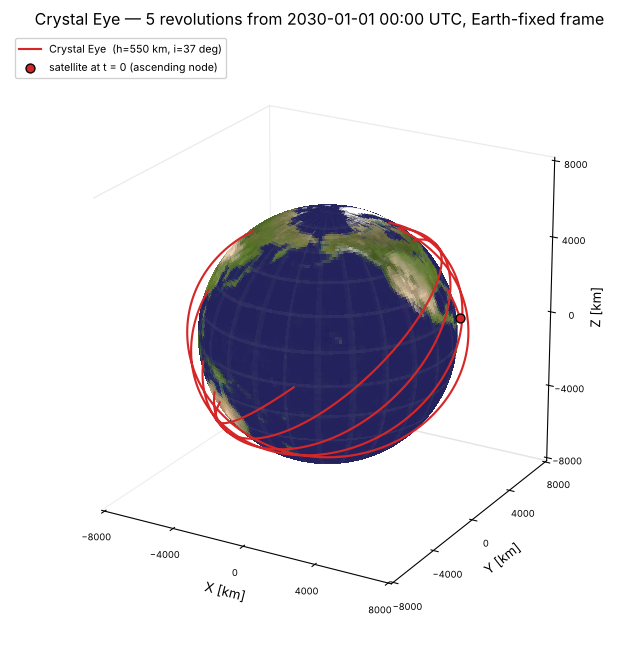

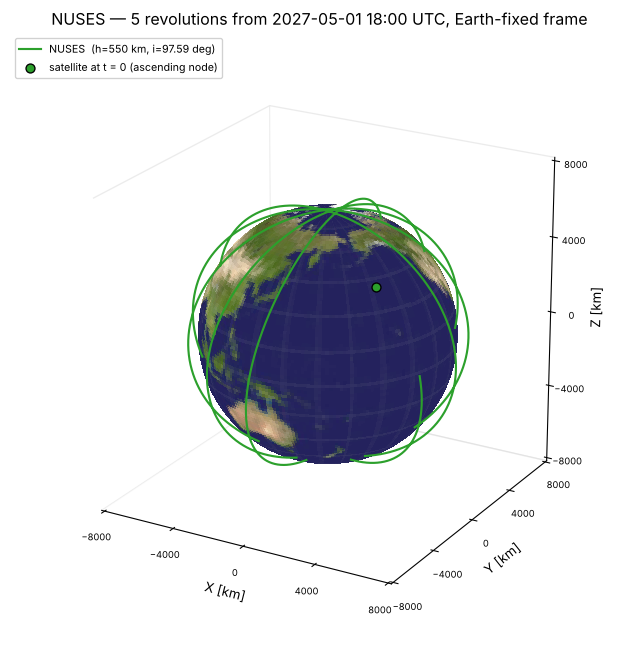

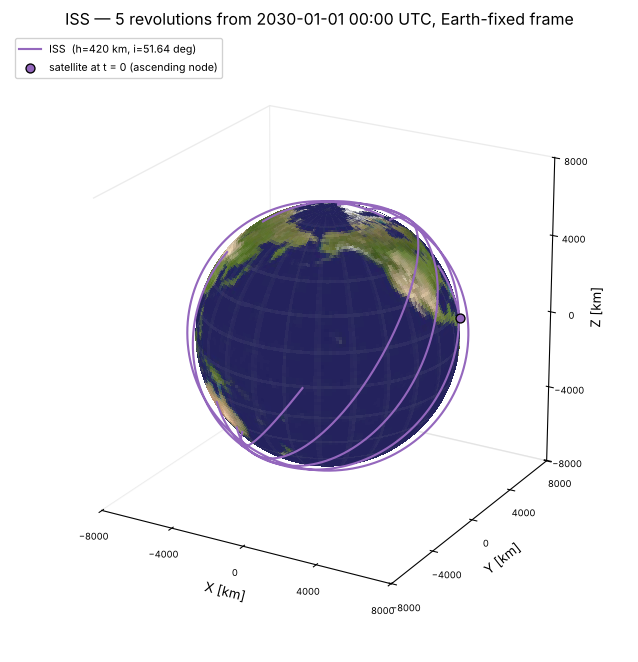

In [6]:
from PIL import Image

_TEXTURE_CACHE = {}

EARTH_GAMMA = 0.62          # <1 brightens the texture (the Blue Marble is very dark)

def earth_texture(nlat=120):
    '''Equirectangular Earth image resampled to a (nlat+1, 2*nlat+1) RGB grid.'''
    if nlat not in _TEXTURE_CACHE:
        img = Image.open(ASSETS / "earth_equirectangular.jpg").convert("RGB")
        img = img.resize((2*nlat + 1, nlat + 1), Image.BILINEAR)
        _TEXTURE_CACHE[nlat] = (np.asarray(img, dtype=float)/255.0)**EARTH_GAMMA
    return _TEXTURE_CACHE[nlat]


def camera_vector(elev, azim):
    '''Unit vector from the Earth centre towards the viewer.'''
    e, a = np.radians(elev), np.radians(azim)
    return np.array([np.cos(e)*np.cos(a), np.cos(e)*np.sin(a), np.sin(e)])


def visible_from(r, elev, azim):
    '''True where a point is NOT hidden behind the Earth disc.

    Same test as the cylindrical eclipse of section 5, with the line of sight
    playing the role of the Sun direction: a point is hidden only if it is on
    the far side AND its distance from the line of sight is below R_earth.
    '''
    cam  = camera_vector(elev, azim)
    proj = np.asarray(r) @ cam
    perp = np.linalg.norm(np.asarray(r) - proj[..., None]*cam, axis=-1)
    return (proj > 0) | (perp > R_EARTH)


def plot_occluded(ax, r, color, elev, azim, lw=1.6, label=None, back_alpha=0.28):
    '''Draw a 3D curve, dimming the part that the Earth hides.'''
    vis  = visible_from(r, elev, azim)
    back, front = np.array(r, float).copy(), np.array(r, float).copy()
    back[vis], front[~vis] = np.nan, np.nan
    ax.plot(*back.T,  lw=lw, color=color, alpha=back_alpha, zorder=1)
    ax.plot(*front.T, lw=lw, color=color, zorder=4, label=label)


NIGHT_LEVEL = 0.18          # how dark the night side is rendered (0 = black)

def draw_earth_3d(ax, gmst=0.0, nlat=120, textured=True, alpha=1.0, sun_dir=None):
    '''Draw the Earth in the ECI frame, rotated by `gmst` [rad].

    If `sun_dir` (a unit vector in ECI) is given, the night side is darkened, so
    that eclipse and illumination can be read straight off the picture.
    '''
    lon = np.linspace(-np.pi, np.pi, 2*nlat + 1)
    lat = np.linspace(np.pi/2, -np.pi/2, nlat + 1)
    LON, LAT = np.meshgrid(lon, lat)
    X = R_EARTH * np.cos(LAT) * np.cos(LON + gmst)
    Y = R_EARTH * np.cos(LAT) * np.sin(LON + gmst)
    Z = R_EARTH * np.sin(LAT) * np.ones_like(LON)
    ax.computed_zorder = False          # respect our own zorder instead of depth sorting
    if textured:
        rgb = earth_texture(nlat)
        if sun_dir is not None:
            s = np.asarray(sun_dir, float); s /= np.linalg.norm(s)
            cosi = (X*s[0] + Y*s[1] + Z*s[2]) / R_EARTH
            shade = NIGHT_LEVEL + (1 - NIGHT_LEVEL)*np.clip(cosi, 0, 1)**0.45
            rgb = np.clip(rgb * shade[..., None], 0, 1)
        ax.plot_surface(X, Y, Z, rstride=1, cstride=1, facecolors=rgb, shade=False,
                        linewidth=0, antialiased=False, alpha=alpha, zorder=2)
    else:
        ax.plot_surface(X, Y, Z, rstride=4, cstride=4, color="#8fb8d8",
                        alpha=0.45, linewidth=0.2, edgecolor="w", zorder=2)


def _equal_3d(ax, lim, zoom=1.0, frame="ECI"):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=zoom)
    sub = f"$_{{{frame}}}$" if frame else ""
    ax.set_xlabel(f"X{sub} [km]"); ax.set_ylabel(f"Y{sub} [km]"); ax.set_zlabel(f"Z{sub} [km]")
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(mpl.ticker.MaxNLocator(4))
        axis.pane.set_facecolor("white"); axis.pane.set_edgecolor("0.85")
    ax.tick_params(labelsize=7)


def terminator_view_azim(when, offset_deg=90.0):
    '''Camera azimuth that puts the day/night terminator edge-on.

    Looking perpendicular to the Sun direction shows the lit hemisphere, the dark
    one and the shadow behind the Earth all at once - the classic eclipse-geometry
    viewpoint.
    '''
    s = sun_unit_eci(when)
    return np.degrees(np.arctan2(s[1], s[0])) + offset_deg


def rotate_z(r, angle):
    '''Rz(-angle) r: vectors seen from a frame turned by `angle` [rad] (may be an array).'''
    c, s = np.cos(angle), np.sin(angle)
    r = np.asarray(r, float)
    return np.stack([c*r[..., 0] + s*r[..., 1], -s*r[..., 0] + c*r[..., 1], r[..., 2]], axis=-1)


def plot_orbit_3d(orbits, n_orbits=1.0, when=None, textured=True, nlat=120,
                  show_sun=False, figsize=(7, 7), elev=22, azim=None,
                  shade_night=False, title=None, frame="eci"):
    '''3D view of one or more orbits around a textured Earth.

    frame = "eci" : inertial frame, Earth rotated by the GMST of `when`.
    frame = "ecef": Earth-fixed frame whose axes coincide with ECI at t = 0: the Earth
                    and the start point look exactly as in the inertial view, and
                    each further revolution is shifted west (in ECI they would overlap).
    The Sun (arrow, night shading) is off by default: it is introduced in section 5.
    '''
    orbits = orbits if isinstance(orbits, (list, tuple)) else [orbits]
    when = when or orbits[0].epoch
    if azim is None:
        azim = terminator_view_azim(when) if (show_sun or shade_night) else -60.0

    fig = plt.figure(figsize=figsize)
    ax  = fig.add_subplot(111, projection="3d")
    ax.set_facecolor("white"); ax.grid(False)
    ax.view_init(elev=elev, azim=azim)
    sun = sun_unit_eci(when)
    draw_earth_3d(ax, gmst=gmst_rad(when), nlat=nlat, textured=textured,
                  sun_dir=sun if shade_night else None)

    lim = R_EARTH
    for orb in orbits:
        t  = time_grid(orb, n_orbits=n_orbits, step_s=orb.period_s/600)
        r  = propagate(orb, t)["r_eci"]
        if frame == "ecef":                  # undo the Earth rotation since t = 0
            r = rotate_z(r, OMEGA_E*t)
        plot_occluded(ax, r, orb.color, elev, azim,
                      label=f"{orb.name}  (h={orb.altitude_km:.0f} km, i={orb.inc_deg:g} deg)")
        ax.scatter(*r[0], s=45, color=orb.color, edgecolor="k", zorder=6, depthshade=False,
                   label="satellite at t = 0 (ascending node)")
        lim = max(lim, orb.a)

    if show_sun:
        p0, p1 = sun*R_EARTH*1.02, sun*lim*1.45
        ax.quiver(*p0, *(p1 - p0), color="goldenrod", lw=2.2,
                  arrow_length_ratio=0.12, zorder=5)
        ax.text(*(p1*1.04), "to Sun", color="goldenrod", fontsize=9, zorder=6)

    _equal_3d(ax, lim*1.18, zoom=0.9, frame="ECI" if frame == "eci" else "")
    ax.set_title(title or f"Orbits in the inertial frame — {when:%Y-%m-%d %H:%M} UTC")
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
    plt.tight_layout()
    return fig, ax


N_ORBITS_3D = 5   # revolutions to draw: 1, 2, 3, ... up to one day (~15)

for orb in ORBITS:                       # one figure per mission, at its own epoch
    n_day = DAY/orb.period_s             # revolutions in one day
    n     = float(min(N_ORBITS_3D, n_day))
    frame = "eci" if n <= 1 else "ecef"  # several revolutions: Earth-fixed frame
    what  = (f"{n:.0f} revolution{'s' if n > 1 else ''}" if n < n_day
             else f"one day ({n_day:.1f} revolutions)")
    fig, ax = plot_orbit_3d(orb, n_orbits=n, frame=frame,
                            title=f"{orb.name} — {what} from "
                                  f"{orb.epoch:%Y-%m-%d %H:%M} UTC, "
                                  f"{'inertial' if frame == 'eci' else 'Earth-fixed'} frame")
    plt.show()


Crystal Eye stays within $\pm37°$ of the equator; NUSES is nearly polar (retrograde,
$i>90°$) and passes within 7.6° of both poles; the ISS sits lower and is more inclined ($51.6°$). The
dot is the satellite at $t = 0$: since $u_0 = 0$, it is on the equator, at the ascending
node. Where the Sun is with respect to these planes is the subject of section 5.

## 4. Seeing the orbit — the ground track

The ground track is the sub-satellite point drawn on the map. Two effects combine:

* the satellite runs along its orbit about 15 times a day;
* the Earth turns underneath at $360°$ per **sidereal** day.

The result is a westward shift of the equator crossings by
$\Delta\lambda = -(\omega_\oplus - \dot\Omega)\,T_n$ per revolution, about $-24°$ of
longitude at 550 km (the J2 drift of the node adds a few tenths of a degree). Note the track is bounded by $|\varphi| \le i$ (or
$180° - i$ for a retrograde orbit): the inclination is directly readable from the map.

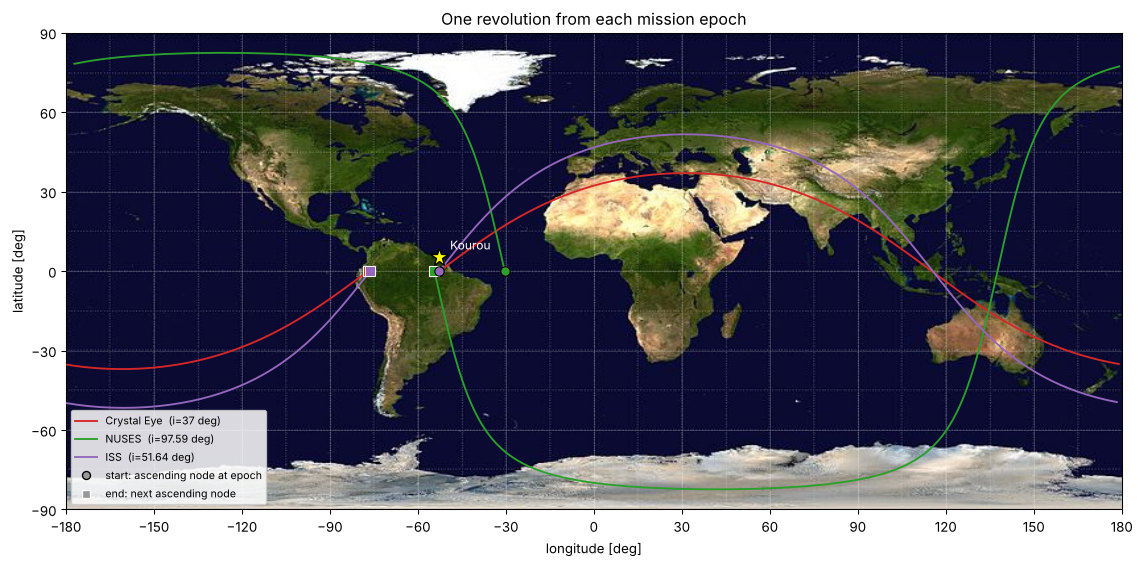

              Earth rotation  J2 node drift  shift per revolution  |lat|max
Crystal Eye           23.93°         -0.39°               -24.32°    37.00°
NUSES                 24.01°         +0.07°               -23.94°    82.41°
ISS                   23.29°         -0.32°               -23.61°    51.64°
shift = -(Earth rotation - J2 node drift): almost all of it is the Earth turning (~24°);
J2 adds a few tenths of a degree (= dW/dt per day / revolutions per day; 0 if USE_J2 = False)


In [7]:
_EARTH_MAP = None

def earth_map():
    global _EARTH_MAP
    if _EARTH_MAP is None:
        _EARTH_MAP = np.asarray(Image.open(ASSETS / "earth_equirectangular.jpg").convert("RGB"))
    return _EARTH_MAP


def basemap(ax=None, figsize=(12, 6), title=None, grid=True):
    '''Blank equirectangular world map, ready to be drawn on (x=lon, y=lat).'''
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.imshow(earth_map(), extent=[-180, 180, -90, 90], aspect="auto",
              interpolation="bilinear", zorder=0)
    if grid:
        ax.set_xticks(np.arange(-180, 181, 30)); ax.set_yticks(np.arange(-90, 91, 30))
        ax.grid(color="w", alpha=0.25, lw=0.5)
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
    ax.set_xlabel("longitude [deg]"); ax.set_ylabel("latitude [deg]")
    if title:
        ax.set_title(title)
    return ax


def split_track(lon, lat):
    '''Insert NaNs where the track wraps at +-180 deg, so plot() does not draw a dateline
    jump across the whole map.'''
    lon, lat = np.asarray(lon, float).copy(), np.asarray(lat, float).copy()
    jump = np.where(np.abs(np.diff(lon)) > 180.0)[0] + 1
    return np.insert(lon, jump, np.nan), np.insert(lat, jump, np.nan)


def plot_ground_track(orbits, n_orbits=1.0, step_s=20.0, ax=None, title=None,
                      figsize=(12, 6), mark_ends=True):
    '''Ground track of each orbit from its own epoch; dots = start and end.'''
    orbits = orbits if isinstance(orbits, (list, tuple)) else [orbits]
    ax = basemap(ax, figsize=figsize, title=title)
    for orb in orbits:
        st = propagate(orb, time_grid(orb, n_orbits, step_s))
        lo, la = split_track(st["lon"], st["lat"])
        ax.plot(lo, la, lw=1.4, color=orb.color, zorder=3,
                label=f"{orb.name}  (i={orb.inc_deg:g} deg)")
        if mark_ends:
            end = propagate(orb, n_orbits*orb.period_s)
            ax.plot(st["lon"][0], st["lat"][0], "o", ms=7, color=orb.color,
                    mec="k", mew=0.8, zorder=4)
            ax.plot(end["lon"][0], end["lat"][0], "s", ms=7, color=orb.color,
                    mec="w", mew=0.8, zorder=4)
    if mark_ends:
        ax.plot([], [], "o", color="0.6", mec="k", label="start: ascending node at epoch")
        ax.plot([], [], "s", color="0.6", mec="w", label="end: next ascending node")
    ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
    return ax


ax = plot_ground_track(ORBITS, n_orbits=1.0,
                       title="One revolution from each mission epoch")
ax.plot(KOUROU_LON, KOUROU_LAT, "*", ms=14, color="yellow", mec="k", zorder=5)
ax.annotate("Kourou", (KOUROU_LON, KOUROU_LAT), textcoords="offset points",
            xytext=(8, 6), color="w", fontsize=9)
plt.tight_layout(); plt.show()

# Why each revolution falls further west: during one revolution (Tn) the Earth turns east
# under the orbit (wE*Tn) and, with J2, the node moves too (dW/dt*Tn). Seen from the ground
# the next equator crossing is shifted by -(wE - dW/dt)*Tn.
print(f"{'':12s} {'Earth rotation':>15s} {'J2 node drift':>14s} {'shift per revolution':>21s}"
      f" {'|lat|max':>9s}")
for orb in ORBITS:
    earth = np.degrees(OMEGA_E * orb.period_s)       # the Earth turns east during one revolution
    j2    = np.degrees(orb.raan_dot * orb.period_s)  # the node moves during the same revolution
    print(f"{orb.name:12s} {earth:14.2f}° {j2:+13.2f}° {-(earth - j2):+20.2f}° {orb.max_latitude_deg:8.2f}°")
print("shift = -(Earth rotation - J2 node drift): almost all of it is the Earth turning (~24°);"
      "\nJ2 adds a few tenths of a degree (= dW/dt per day / revolutions per day; 0 if USE_J2 = False)")


### 4.1 One day of coverage

Over a full day the picture changes completely: the track fills a band whose width is set
by the inclination. This band *is* the part of the Earth the instrument flies over.

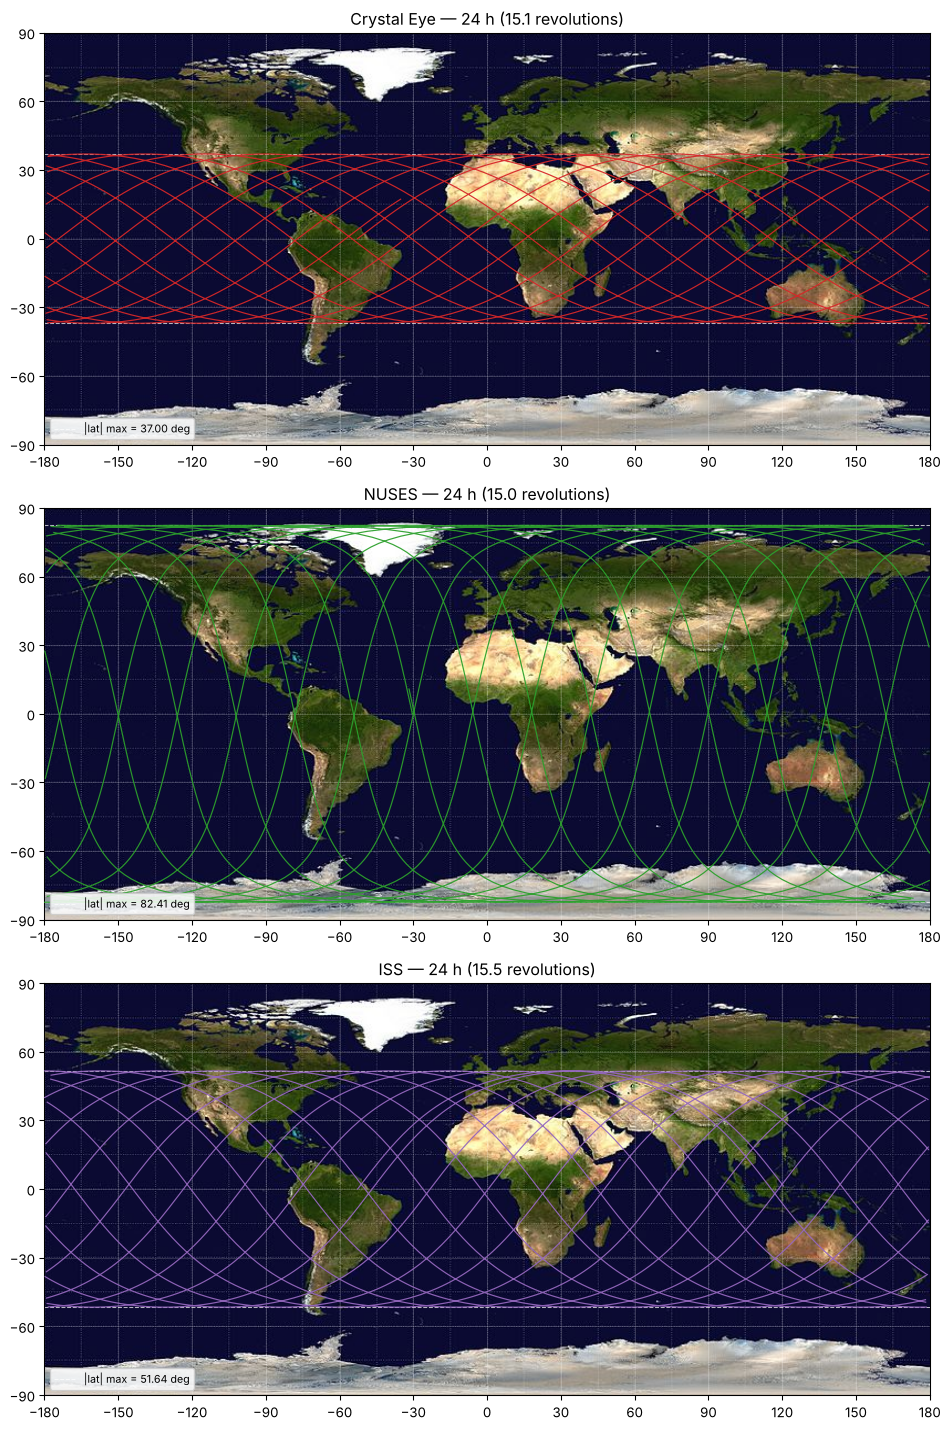

In [8]:
fig, axes = plt.subplots(len(ORBITS), 1, figsize=(10, 5.0*len(ORBITS)))
for orb, ax in zip(ORBITS, axes.ravel()):
    st = propagate(orb, np.arange(0, DAY, 30.0))
    lo, la = split_track(st["lon"], st["lat"])
    basemap(ax, title=f"{orb.name} — 24 h ({orb.orbits_per_day:.1f} revolutions)")
    ax.plot(lo, la, lw=0.9, color=orb.color, alpha=0.95, zorder=3)
    ax.axhline( orb.max_latitude_deg, color="w", ls="--", lw=0.8, alpha=0.7, zorder=2,
               label=f"|lat| max = {orb.max_latitude_deg:.2f} deg")
    ax.axhline(-orb.max_latitude_deg, color="w", ls="--", lw=0.8, alpha=0.7, zorder=2)
    ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()


## 5. Darkness: the beta angle and eclipses

Knowing when the satellite is in the Earth's shadow matters for two very different
reasons. For the platform it is a power and thermal question. For a payload it can be an
*observing* question: detectors that must not see the illuminated Earth limb, or that
simply cannot be operated in daylight, have their duty cycle set by the eclipse pattern.

Everything is governed by one number, the **beta angle** $\beta$: the angle between the
Sun direction and the orbital plane,

$$\sin\beta = \hat{\mathbf s}\cdot\hat{\mathbf h},
\qquad
\hat{\mathbf h}=\begin{pmatrix}\sin i\sin\Omega\\ -\sin i\cos\Omega\\ \cos i\end{pmatrix}$$

where $\hat{\mathbf h}$ is the orbit normal. When $\beta = 0$ the Sun lies in the orbital
plane and the satellite ploughs through the deepest possible shadow; as $|\beta|$ grows
the shadow chord shortens, until at

$$|\beta| > \beta^{*} = \arcsin\!\left(\frac{R_\oplus}{a}\right)$$

the orbit misses the shadow entirely and the satellite is in **full sun** for days or
weeks at a time.

$\beta$ is not constant: the Sun moves along the ecliptic ($\sim 1°$/day) while J2 drags
the node around ($\dot\Omega$, section 1). What matters is the motion of the node
*relative to the Sun*: $\beta$ completes a cycle every $360°/|\dot\Omega - 0.9856°/\mathrm{day}|$
— about 52 days for Crystal Eye, 61 for the ISS, and never for a sun-synchronous orbit,
where only the seasons remain.

In [9]:
def jcent(orb, t_s):
    '''Julian centuries since J2000 for an array of seconds after orb.epoch.'''
    return (julian_date(orb.epoch) + np.asarray(t_s)/DAY - 2451545.0) / 36525.0


def orbit_normal(orb, t_s):
    '''Unit orbit-normal vector in ECI, including the J2 drift of the node.'''
    raan = np.radians(orb.raan_deg) + orb.raan_dot*np.asarray(t_s, float)
    i = np.radians(orb.inc_deg)
    return np.stack([np.sin(i)*np.sin(raan),
                    -np.sin(i)*np.cos(raan),
                     np.cos(i)*np.ones_like(raan)], axis=-1)


def beta_angle(orb, t_s):
    '''Beta angle [deg] at times `t_s` (seconds after epoch). Always returns an array.'''
    t_s = np.atleast_1d(np.asarray(t_s, float))
    s = sun_unit_eci(jcent(orb, t_s))
    h = orbit_normal(orb, t_s)
    return np.degrees(np.arcsin(np.clip(np.sum(s*h, axis=-1), -1, 1)))


def beta_critical(orb):
    '''|beta| above which the orbit never enters the Earth shadow [deg].'''
    return np.degrees(np.arcsin(R_EARTH/orb.a))


def eclipse_fraction(orb, beta_deg):
    '''Fraction of the revolution spent in the cylindrical umbra, from beta alone.

    cos(half-eclipse arc) = cos(rho)/cos(beta), with rho = arcsin(R_earth/a).
    '''
    c = np.cos(np.arcsin(R_EARTH/orb.a)) / np.cos(np.radians(np.abs(beta_deg)))
    frac = np.where(np.abs(c) < 1.0, np.arccos(np.clip(c, -1, 1))/np.pi, 0.0)
    return frac if np.ndim(beta_deg) else float(frac)


for orb in ORBITS:
    b0 = beta_angle(orb, 0.0)[0]
    print(f"{orb.name:22s} beta(epoch) = {b0:+7.2f} deg | beta* = {beta_critical(orb):5.2f} deg")


Crystal Eye            beta(epoch) =   +7.64 deg | beta* = 67.02 deg
NUSES                  beta(epoch) =  +52.82 deg | beta* = 67.02 deg
ISS                    beta(epoch) =  +19.72 deg | beta* = 69.75 deg


### 5.1 Is the satellite in shadow *right now*?

The formula above gives a duration; to flag a specific instant we use the geometry of a
**cylindrical shadow** of radius $R_\oplus$ behind the Earth. The satellite is in eclipse if

* it is on the night side, $\mathbf r\cdot\hat{\mathbf s} < 0$, and
* its distance from the shadow axis is smaller than $R_\oplus$.

The Sun's finite size (penumbra) changes the result by a few seconds per orbit and is
neglected.

At the point of the orbit closest to the shadow axis this distance is $a\sin|\beta|$: if
$a\sin|\beta| > R_\oplus$ the satellite never enters the shadow. This is the condition of
slide 15, and it gives $\beta^{*} = \rho$.

In [10]:
def eclipse_state(orb, t_s):
    '''True where the satellite is inside the cylindrical Earth shadow.'''
    r    = propagate(orb, t_s)["r_eci"]
    s    = sun_unit_eci(jcent(orb, t_s))
    proj = np.sum(r*s, axis=-1)                                 # r . s
    perp = np.linalg.norm(r - proj[..., None]*s, axis=-1)       # distance from shadow axis
    return (proj < 0) & (perp < R_EARTH)


def eclipse_report(orb, n_orbits=1.0, step_s=1.0, t0=0.0):
    t   = t0 + np.arange(0.0, n_orbits*orb.period_s, step_s)
    ecl = eclipse_state(orb, t)
    b   = beta_angle(orb, t0)[0]
    return dict(t=t, eclipse=ecl, beta=b,
                numeric_min=ecl.sum()*step_s/60,
                analytic_min=eclipse_fraction(orb, b)*orb.period_s/60)


print(f"{'orbit':22s} {'beta':>7s} {'numeric':>9s} {'analytic':>9s}   "
      f"(eclipse minutes on the first revolution)")
print("-"*66)
for orb in ORBITS:
    rep = eclipse_report(orb, n_orbits=1.0, step_s=1.0)
    print(f"{orb.name:22s} {rep['beta']:+7.2f} {rep['numeric_min']:9.2f} {rep['analytic_min']:9.2f}")

orbit                     beta   numeric  analytic   (eclipse minutes on the first revolution)
------------------------------------------------------------------
Crystal Eye              +7.64     35.35     35.42
NUSES                   +52.82     26.47     26.47
ISS                     +19.72     35.25     35.32


The figure below shows one revolution per mission: sunlight in yellow, eclipse in dark.


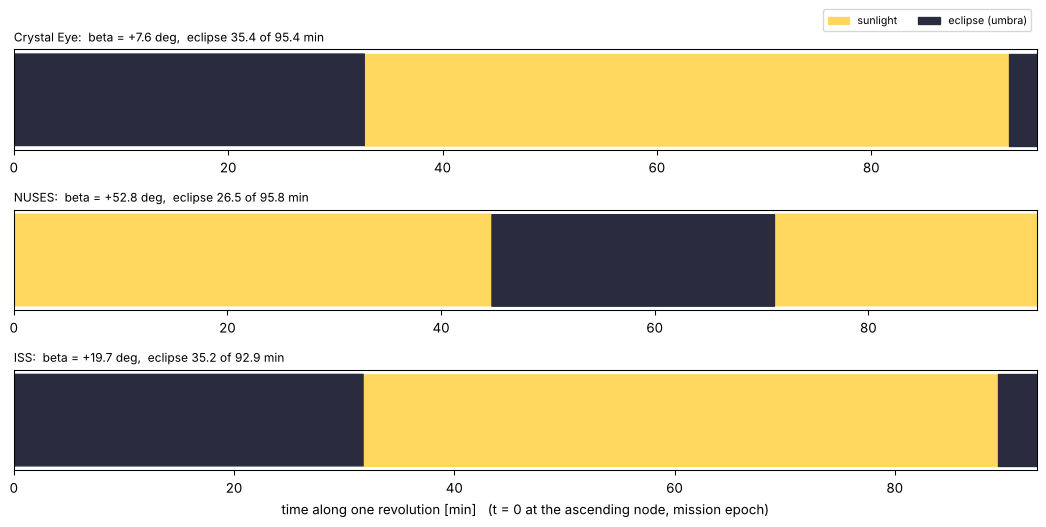

In [11]:
# --- one revolution per mission: when is the satellite in sunlight, when in shadow ----
fig, axes = plt.subplots(len(ORBITS), 1, figsize=(11, 1.9*len(ORBITS)), sharex=False)
for orb, ax in zip(ORBITS, axes):
    rep = eclipse_report(orb, n_orbits=1.0, step_s=1.0)
    tm  = rep["t"]/60
    ax.fill_between(tm, 0, 1, where=~rep["eclipse"], color="#ffd75e", step="mid")
    ax.fill_between(tm, 0, 1, where=rep["eclipse"],  color="#2b2b40", step="mid")
    ax.set_yticks([]); ax.set_xlim(0, orb.period_s/60); ax.grid(False)
    ax.set_title(f"{orb.name}:  beta = {rep['beta']:+.1f} deg,  "
                 f"eclipse {rep['numeric_min']:.1f} of {orb.period_s/60:.1f} min",
                 fontsize=9, loc="left", color="k")
axes[-1].set_xlabel("time along one revolution [min]   (t = 0 at the ascending node, mission epoch)")
axes[0].legend(handles=[mpl.patches.Patch(color="#ffd75e", label="sunlight"),
                        mpl.patches.Patch(color="#2b2b40", label="eclipse (umbra)")],
               loc="upper right", fontsize=8, ncol=2, bbox_to_anchor=(1, 1.45))
plt.tight_layout(); plt.show()

### 5.2 The whole mission: beta angle and eclipse duration

One figure per mission, over its own mission window. Look for the three time scales: the
Sun's yearly march, the motion of the node relative to the Sun, and their beat.

orbit                   beta min  beta max  ecl. min  ecl. mean  ecl. max  full-sun days
----------------------------------------------------------------------------------------


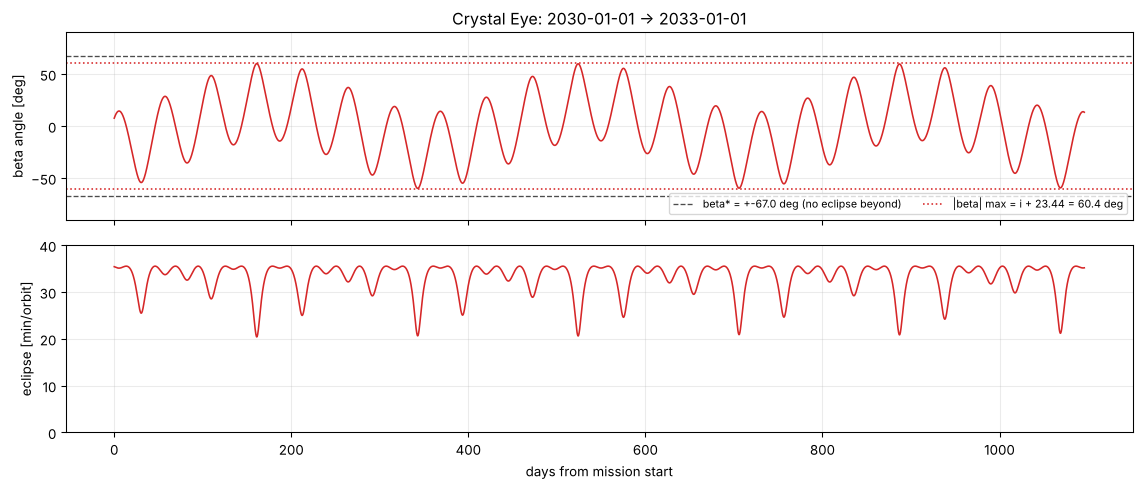

Crystal Eye               -59.86    +60.07     20.42      33.10     35.54            0.0


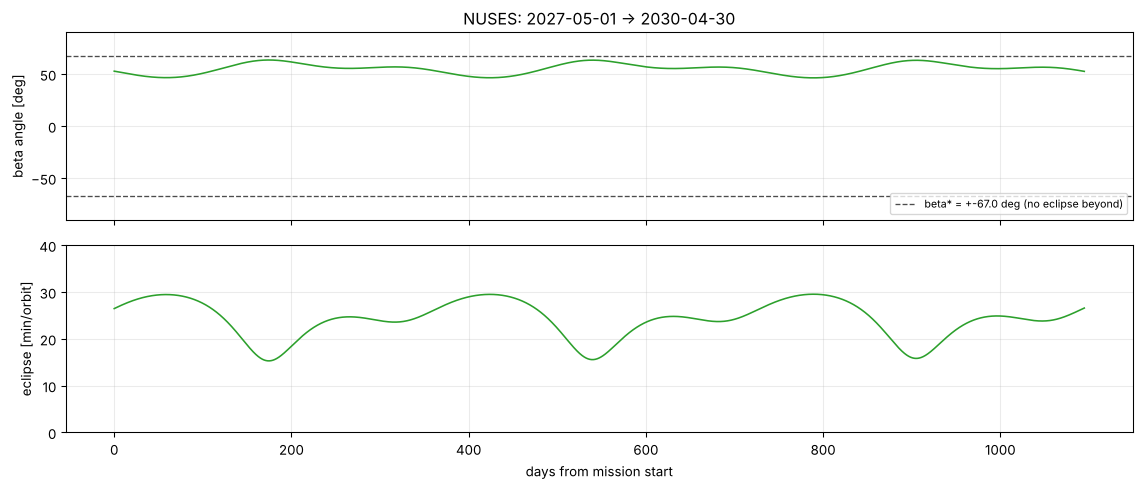

NUSES                     +46.39    +63.55     15.29      24.18     29.54            0.0


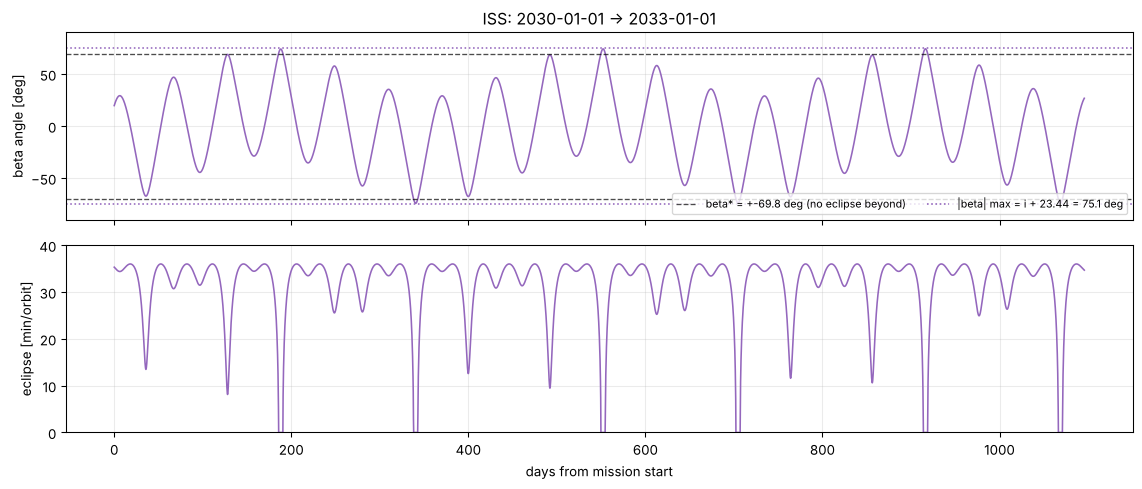

ISS                       -74.27    +74.35      0.00      31.50     36.00           29.5


In [12]:
print(f"{'orbit':22s} {'beta min':>9s} {'beta max':>9s} {'ecl. min':>9s} {'ecl. mean':>10s} "
      f"{'ecl. max':>9s} {'full-sun days':>14s}")
print("-"*88)
for orb in ORBITS:
    days = np.arange(0.0, orb.duration_days, 0.25)
    b    = beta_angle(orb, days*DAY)
    ecl  = eclipse_fraction(orb, b)*orb.period_s/60
    bc   = beta_critical(orb)
    bmax = orb.max_latitude_deg + OBLIQUITY        # |beta| can never exceed i + 23.44 deg

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
    ax1.plot(days, b, lw=1.2, color=orb.color)
    for sgn in (1, -1):
        ax1.axhline(sgn*bc, color="k", ls="--", lw=1, alpha=0.7,
                    label=f"beta* = +-{bc:.1f} deg (no eclipse beyond)" if sgn > 0 else None)
        if bmax < 90:
            ax1.axhline(sgn*bmax, color=orb.color, ls=":", lw=1.2,
                        label=f"|beta| max = i + 23.44 = {bmax:.1f} deg" if sgn > 0 else None)
    ax1.set_ylabel("beta angle [deg]"); ax1.set_ylim(-90, 90)
    ax1.legend(fontsize=8, loc="lower right", ncol=2)
    ax1.set_title(f"{orb.name}: {orb.start:%Y-%m-%d} -> {orb.end:%Y-%m-%d}")
    ax2.plot(days, ecl, lw=1.2, color=orb.color)
    ax2.set_ylabel("eclipse [min/orbit]"); ax2.set_ylim(0, 40)
    ax2.set_xlabel("days from mission start")
    plt.tight_layout(); plt.show()

    print(f"{orb.name:22s} {b.min():+9.2f} {b.max():+9.2f} {ecl.min():9.2f} {ecl.mean():10.2f} "
          f"{ecl.max():9.2f} {(ecl == 0).sum()*0.25:14.1f}")

### 5.3 What to take away


* **The sun-synchronous orbit.** By construction its node follows the Sun, so $\beta$ drifts slowly and the eclipse duration stays between 15 and 30 min
  all mission long. Stable power and thermal conditions and a fixed local time are among the
  reasons SSOs are chosen.
* **Crystal Eye and the ISS.** Their node moves by several degrees per day with
  respect to the Sun, so $\beta$ sweeps its whole range in 52 (Crystal Eye) and 61 (ISS)
  days, and with it the eclipse duration.
* **Full-sun periods.** They occur only if $|\beta|$ can
  exceed $\beta^{*}$. Since $|\beta| \le i + 23.44°$, Crystal Eye ($|\beta| \le 60° < \beta^*=67°$)
  is eclipsed on every revolution; the ISS ($|\beta|$ up to 75° $> \beta^*=69.8°$) has about
  30 days of full sun in three years.

A useful check: at $\beta = 0$ the eclipse fraction is simply $\rho/180°$, with
$\rho = \arcsin(R_\oplus/a)$ — 37.2 % at 550 km, i.e. 35.5 min of a 95.4-min revolution
(ISS: 38.8 %, 36.0 min). If your own calculation lands far from that, look for a factor
$\cos\beta$ or a sidereal/solar day mix-up.

## 6. From the orbit to the sky: the coordinate chain

To know which part of the sky an astronomical detector observes we need a chain of changes of frame:

$$
\underbrace{\mathbf r_{\rm orb}}_{\text{orbital plane}}
\;\xrightarrow{\;R_z(\Omega)\,R_x(i)\;}\;
\underbrace{\mathbf r_{\rm ECI}}_{\text{inertial}}
\;\xrightarrow{\;\text{unit vector}\;}\;
(\alpha,\delta)
\;\xrightarrow{\;R_{\rm gal}\;}\;
(l,b)
\;\xrightarrow{\;\text{Mollweide}\;}\;
(x,y)
$$

$$
\hat{\mathbf k}_{\rm ECI}\;\xrightarrow{\;Q^{T}\;}\;\hat{\mathbf k}_{\rm sat},
\qquad Q = R_z(\Omega)\,R_x(i)\,R_z(u)
$$

1. **Orbital plane → ECI.** For a circular orbit $\mathbf r_{\rm orb}=a(\cos u,\sin u,0)$ and
   $\mathbf r_{\rm ECI}=R_z(\Omega)\,R_x(i)\,\mathbf r_{\rm orb}$ — exactly what `propagate`
   does, written as matrices. These are **active** rotations: we *build* the ECI
   coordinates of a point known in the orbital plane.
2. **ECI → equatorial.** Any unit vector is a direction on the sky:
   $\delta=\arcsin z$, $\alpha=\operatorname{atan2}(y,x)$. The zenith of a nadir-pointing
   spacecraft is simply $\hat{\mathbf r}$.
3. **Equatorial → galactic.** A fixed rotation $R_{\rm gal}$ whose rows are the galactic axes
   written in equatorial coordinates: $\hat z_{\rm gal}$ = North Galactic Pole,
   $\hat x_{\rm gal}$ = Galactic Centre, $\hat y_{\rm gal}=\hat z\times\hat x$.
4. **Galactic → Mollweide.** An equal-area projection of the whole sphere on an ellipse —
   the standard for all-sky maps, because an exposure *per unit solid angle* keeps its
   meaning on it.
5. **ECI → satellite frame.** The columns of $Q$ are the zenith, the along-track direction
   and the orbit normal. A source direction $\hat{\mathbf k}$ (ECI) seen from the satellite is
   $\hat{\mathbf k}_{\rm sat}=Q^{T}\hat{\mathbf k}$: the zenith angle $\theta=\arccos(\hat{\mathbf k}\cdot\hat{\mathbf r})$ and the
   cross-track component $\sin\beta_{\rm src}$ used in section 9.

> **Keplerian orbits from here to section 8.** To see the geometry first in its simplest
> form, sections 6–8 use the **Keplerian** version of each mission (`CE_K`, `NUSES_K`,
> `ISS_K`): fixed orbital plane, period $T_k$, whatever `USE_J2` says. The same zenith
> circle then repeats on every revolution for the whole mission. Section 9 switches J2 back
> on and compares.


In [13]:
# Sections 6-8: the sky on the Keplerian orbits (fixed orbital plane, period Tk).
# J2 is switched back on in section 9.
CE_K, NUSES_K, ISS_K = (keplerian(o) for o in (CE, NUSES, ISS))
ORBITS_K = [CE_K, NUSES_K, ISS_K]
for o in ORBITS_K:
    print(f"{o.name:22s} Keplerian: period Tk = {o.period_s/60:.3f} min, nodal drift "
          f"{o.raan_dot_deg_day + 0.0:+.1f} deg/day, RAAN fixed at {o.raan_deg % 360:.2f} deg")

Crystal Eye            Keplerian: period Tk = 95.650 min, nodal drift +0.0 deg/day, RAAN fixed at 48.04 deg
NUSES                  Keplerian: period Tk = 95.650 min, nodal drift +0.0 deg/day, RAAN fixed at 99.05 deg
ISS                    Keplerian: period Tk = 92.970 min, nodal drift +0.0 deg/day, RAAN fixed at 48.04 deg


In [14]:
def Rx(a):
    '''Active rotation by angle a [rad] about X.'''
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def Rz(a):
    '''Active rotation by angle a [rad] about Z.'''
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def sph_to_unit(lon_deg, lat_deg):
    '''(longitude, latitude) [deg] -> unit vector; works on arrays.'''
    lo, la = np.radians(lon_deg), np.radians(lat_deg)
    return np.stack([np.cos(la)*np.cos(lo), np.cos(la)*np.sin(lo), np.sin(la)], axis=-1)

def unit_to_sph(v):
    '''unit vector(s) -> (longitude in [0,360), latitude) [deg].'''
    v = np.asarray(v, float)
    v = v / np.linalg.norm(v, axis=-1, keepdims=True)
    return (np.degrees(np.arctan2(v[..., 1], v[..., 0])) % 360.0,
            np.degrees(np.arcsin(np.clip(v[..., 2], -1, 1))))

radec_to_unit, unit_to_radec = sph_to_unit, unit_to_sph      # same maths, two names


# ---- IAU galactic frame, in ICRS (J2000) ------------------------------------
RA_NGP, DEC_NGP = 192.85948, 27.12825      # North Galactic Pole
RA_GC,  DEC_GC  = 266.40499, -28.93617     # Galactic Centre (l = 0, b = 0)

def build_R_gal():
    '''Rows = galactic x, y, z axes written in equatorial coordinates.'''
    z = radec_to_unit(RA_NGP, DEC_NGP)
    x = radec_to_unit(RA_GC, DEC_GC)
    x = x - (x @ z)*z;  x /= np.linalg.norm(x)       # Gram-Schmidt: x exactly _|_ z
    y = np.cross(z, x)
    return np.vstack([x, y, z])

R_GAL = build_R_gal()

# a few landmarks used on every map (RA, Dec in J2000)
SOURCES = {
    "Crab Nebula":      (83.633, 22.0145),
    "Sgr A*":           (266.4168, -29.0078),
    "Cyg X-1":          (299.5903, 35.2016),
    "Sco X-1":          (244.9795, -15.6403),
}

def eci_to_gal(v):  return np.asarray(v) @ R_GAL.T   # row vectors: v_gal = R_gal v_eci
def gal_to_eci(v):  return np.asarray(v) @ R_GAL     # inverse = transpose
def unit_to_lb(v_eci):          return unit_to_sph(eci_to_gal(v_eci))
def radec_to_lb(ra, dec):       return unit_to_lb(radec_to_unit(ra, dec))
def lb_to_unit_eci(l, b):       return gal_to_eci(sph_to_unit(l, b))


np.set_printoptions(precision=6, suppress=True)
print("R_gal  (rows = galactic axes in equatorial coordinates)\n", R_GAL)
print(f"R_gal R_gal^T = I : max error {np.abs(R_GAL @ R_GAL.T - np.eye(3)).max():.1e}"
      f"   det = {np.linalg.det(R_GAL):+.6f}")

print("\nChecks against the IAU definition and the catalogue")
for name, (ra, dec), ref in [("Galactic Centre", (RA_GC, DEC_GC), (0.0, 0.0)),
                            ("North Galactic Pole", (RA_NGP, DEC_NGP), (None, 90.0)),
                            ("Crab Nebula", SOURCES["Crab Nebula"], (184.5575, -5.7843))]:
    l, b = radec_to_lb(ra, dec)
    l = l if l < 359.999 else l - 360
    ref_l = "   --   " if ref[0] is None else f"{ref[0]:8.4f}"
    l_txt = "undefined" if ref[0] is None else f"{l:8.4f} "   # at b = 90 deg l has no meaning
    print(f"  {name:20s} l = {l_txt}  b = {b:+8.4f}    (expected l = {ref_l}, b = {ref[1]:+8.4f})")

# unit_to_sph must also work on many vectors at once, shape (N, 3): two directions in one call
_two = np.array([radec_to_unit(RA_GC, DEC_GC), radec_to_unit(*SOURCES["Crab Nebula"])])
try:
    _l2, _b2 = unit_to_lb(_two)
    _ok = np.shape(_b2) == (2,) and np.allclose(_b2, [0.0, -5.7844], atol=1e-3) and abs(_l2[1] - 184.5574) < 1e-3
except Exception:
    _ok = False
print("  two directions in one call (array of shape (2, 3)):",
      "OK" if _ok else "WRONG -> in unit_to_sph use v[..., 0], v[..., 1], v[..., 2]")


R_gal  (rows = galactic axes in equatorial coordinates)
 [[-0.054876 -0.873437 -0.483835]
 [ 0.494109 -0.44483   0.746982]
 [-0.867666 -0.198076  0.455984]]
R_gal R_gal^T = I : max error 2.2e-16   det = +1.000000

Checks against the IAU definition and the catalogue
  Galactic Centre      l =   0.0000   b =  +0.0000    (expected l =   0.0000, b =  +0.0000)
  North Galactic Pole  l = undefined  b = +90.0000    (expected l =    --   , b = +90.0000)
  Crab Nebula          l = 184.5574   b =  -5.7844    (expected l = 184.5575, b =  -5.7843)
  two directions in one call (array of shape (2, 3)): OK


### 6.1 The chain, one step at a time

We follow the **zenith** of Crystal Eye ($i=37°$) through the frames at four instants of
the first revolution: $t = 0,\ T/4,\ T/2,\ 3T/4$ ($T = T_k$: Keplerian orbit), i.e. $u = 0°, 90°, 180°, 270°$ (ascending
node, northernmost point, descending node, southernmost point). At $t = T/4$, the zenith must reach $\delta = +i$.

The rotation $Q = R_z(\Omega)R_x(i)R_z(u)$ has as its three columns the **zenith**, the
**along-track** direction and the **orbit normal**, the local orbital frame of the
satellite, and we will use it to see the Crab from the spacecraft.

In [15]:
# worked example: one mission, a few instants -- try orb = NUSES_K or orb = ISS_K
orb = CE_K

# --- the zenith at four key points of one revolution ---------------------------------
print(f"{orb.name}: zenith at four instants of one revolution (T = {orb.period_s/60:.3f} min)\n")
print(f"{'t':>10s} {'u':>7s} {'RA':>8s} {'Dec':>8s} {'expected Dec':>13s} {'l':>8s} {'b':>8s}  [deg]")
for frac, what in [(0.0, "ascending node"), (0.25, "northernmost"),
                   (0.5, "descending node"), (0.75, "southernmost")]:
    t_k  = frac*orb.period_s
    st_k = propagate(orb, t_k)
    u_k  = np.degrees(st_k["u"][0]) % 360
    ra_k, dec_k = unit_to_radec(st_k["r_eci"][0])
    l_k, b_k    = radec_to_lb(ra_k, dec_k)
    dec_exp = np.degrees(np.arcsin(np.sin(np.radians(orb.inc_deg))*np.sin(st_k["u"][0])))
    dec_k, dec_exp = np.round(dec_k, 3) + 0.0, np.round(dec_exp, 3) + 0.0   # no "-0.000"
    print(f"{frac:6.2f} T  {u_k:7.2f} {ra_k:8.3f} {dec_k:+8.3f} {dec_exp:+13.3f} "
          f"{l_k:8.3f} {b_k:+8.3f}   {what}")

# --- full chain at t = T/4 ------------------------------------------------------------
t_chain = orb.period_s/4
st = propagate(orb, t_chain)
u, W, inc = st["u"][0], st["raan"][0], np.radians(orb.inc_deg)

# 1. orbital plane -> ECI
r_orb = orb.a * np.array([np.cos(u), np.sin(u), 0.0])
R_W, R_i = Rz(W), Rx(inc)
r_eci = R_W @ R_i @ r_orb
print(f"\nFull chain at t = T/4 = {t_chain:.1f} s   u = {np.degrees(u)%360:.3f} deg"
      f"   RAAN = {np.degrees(W)%360:.3f} deg   i = {orb.inc_deg} deg\n")
print("Rz(RAAN) =\n", R_W, "\nRx(i) =\n", R_i)
print(f"\n1. r_orb = {r_orb} km")
print(f"   r_ECI = Rz(W) Rx(i) r_orb = {r_eci} km")
print(f"   ...and from propagate():   {st['r_eci'][0]} km   "
      f"(difference {np.linalg.norm(r_eci - st['r_eci'][0])*1e3:.1e} m)")

Q = R_W @ R_i @ Rz(u)
print("\n   Q = Rz(W) Rx(i) Rz(u): columns = zenith | along-track | orbit normal\n", Q)

# 2. ECI -> (RA, Dec)
r_hat = r_eci / np.linalg.norm(r_eci)                # the zenith, r-hat
ra_zen, dec_zen = unit_to_radec(r_hat)
print(f"\n2. zenith  RA = {ra_zen:8.3f} deg   Dec = {dec_zen:+8.3f} deg"
      f"   (expected: arcsin(sin i) = {np.degrees(np.arcsin(np.sin(inc))):+.3f} deg)")

# 3. (RA, Dec) -> (l, b)
l_zen, b_zen = radec_to_lb(ra_zen, dec_zen)
print(f"3. zenith  l  = {l_zen:8.3f} deg   b   = {b_zen:+8.3f} deg")
print("4. (l, b) -> Mollweide (x, y): done by matplotlib, see 6.2")

# 5. ECI -> satellite frame: a source seen from the spacecraft
k_crab = radec_to_unit(*SOURCES["Crab Nebula"])            # Crab Nebula, unit vector k-hat in ECI
k_sat  = Q.T @ k_crab                                # components: zenith, along-track, normal
theta     = np.degrees(np.arccos(np.clip(k_sat[0], -1, 1)))   # zenith angle theta = arccos(k_hat . r_hat)
beta_src  = np.degrees(np.arcsin(np.clip(k_sat[2], -1, 1)))
print(f"\n5. Crab in the satellite frame: k_sat = {k_sat}  (zenith, along-track, normal)")
print(f"   zenith angle theta = {theta:6.2f} deg"
      f"   cross-track component -> beta_src = {beta_src:+.2f} deg (section 9)")

Crystal Eye: zenith at four instants of one revolution (T = 95.650 min)

         t       u       RA      Dec  expected Dec        l        b  [deg]
  0.00 T     0.00   48.042   +0.000        +0.000  180.036  -46.670   ascending node
  0.25 T    90.00  138.042  +37.000       +37.000  186.408  +43.153   northernmost
  0.50 T   180.00  228.042   +0.000        +0.000    0.036  +46.670   descending node
  0.75 T   270.00  318.042  -37.000       -37.000    6.408  -43.153   southernmost

Full chain at t = T/4 = 1434.7 s   u = 90.000 deg   RAAN = 48.042 deg   i = 37.0 deg

Rz(RAAN) =
 [[ 0.66859  -0.743631  0.      ]
 [ 0.743631  0.66859   0.      ]
 [ 0.        0.        1.      ]] 
Rx(i) =
 [[ 1.        0.        0.      ]
 [ 0.        0.798636 -0.601815]
 [ 0.        0.601815  0.798636]]

1. r_orb = [   0.    6928.137    0.   ] km
   r_ECI = Rz(W) Rx(i) r_orb = [-4114.553607  3699.345865  4169.456929] km
   ...and from propagate():   [-4114.553607  3699.345865  4169.456929] km   (differenc

### 6.2 The Mollweide projection, and the map convention

The projection is defined implicitly: solve $2\psi+\sin2\psi=\pi\sin\varphi$ for the
auxiliary angle $\psi$ (Newton's method), then
$x=\frac{2\sqrt2}{\pi}\lambda\cos\psi$, $y=\sqrt2\sin\psi$. Matplotlib implements it
(`projection="mollweide"`); below we only fix the map convention.


In [16]:
MAP_CENTER_L = 180.0        # longitude at the centre of every sky map [deg]

def lon_to_x(lon_deg):
    '''Sky longitude -> matplotlib Mollweide x [rad]: centred, increasing to the left.'''
    return np.radians(((MAP_CENTER_L - np.asarray(lon_deg) + 180.0) % 360.0) - 180.0)

def x_to_lon(x_rad):
    return (MAP_CENTER_L - np.degrees(x_rad)) % 360.0

In [17]:
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

SKY_BG   = "#0b0b16"
SKY_TXT  = "white"
_STROKE  = [pe.withStroke(linewidth=2.5, foreground=SKY_BG)]

def plot_lb(ax, l, b, **kw):
    '''Draw a curve given in (l, b) [deg], breaking it where it wraps around the map.'''
    x, y = lon_to_x(l), np.radians(b)
    cut = np.flatnonzero(np.abs(np.diff(x)) > np.pi) + 1
    label = kw.pop("label", None)
    for seg in np.split(np.arange(len(x)), cut):
        if len(seg) > 1:
            ax.plot(x[seg], y[seg], label=label, **kw)
            label = None                         # legend entry only once


def eci_to_map(v_eci, frame="gal"):
    '''ECI unit vector(s) -> map (longitude, latitude) [deg]: (l, b) or (RA, Dec).'''
    return unit_to_lb(v_eci) if frame == "gal" else unit_to_radec(v_eci)


def plot_eci_curve(ax, v_eci, frame="gal", **kw):
    l, b = eci_to_map(v_eci, frame)
    plot_lb(ax, l, b, **kw)


def mark_eci(ax, v_eci, text=None, offset=(6, 5), frame="gal", **kw):
    l, b = eci_to_map(v_eci, frame)
    ax.plot(lon_to_x(l), np.radians(b), **kw)
    if text:
        ax.annotate(text, (lon_to_x(l), np.radians(b)), textcoords="offset points",
                    xytext=offset, color=SKY_TXT, fontsize=8, path_effects=_STROKE, zorder=12)


def sky_axes(ax=None, figsize=(11, 5.8), title=None, galactic_plane=True,
             equator=True, ecliptic=False, landmarks=True, fontsize=8, frame="gal"):
    '''An empty Mollweide sky map, dark theme: galactic (l, b) or equatorial (RA, Dec).'''
    if ax is None:
        fig = plt.figure(figsize=figsize, facecolor=SKY_BG)
        ax = fig.add_subplot(111, projection="mollweide")
    ax.figure.set_facecolor(SKY_BG)
    ax.set_facecolor("#14142a")
    xt = np.radians(np.arange(-150, 151, 30))
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{x_to_lon(x):.0f}°" for x in xt])
    yt = np.radians(np.arange(-75, 76, 15))
    ax.set_yticks(yt)
    ax.set_yticklabels([f"{d:+d}°" if d else "0°" for d in range(-75, 76, 15)])
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_color(SKY_TXT); lab.set_fontsize(fontsize); lab.set_path_effects(_STROKE)
    ax.grid(color="#6a6a9a", alpha=0.35, lw=0.5)

    if galactic_plane:
        plot_eci_curve(ax, lb_to_unit_eci(np.linspace(0, 360, 721), np.zeros(721)),
                       frame=frame, color="w", lw=1.6, alpha=0.75, zorder=4,
                       label="Galactic plane")
    if equator:
        plot_eci_curve(ax, radec_to_unit(np.linspace(0, 360, 721), np.zeros(721)),
                       frame=frame, color="#ff8800", lw=1.6, ls="--", alpha=0.9, zorder=4,
                       label="Celestial equator")
    if ecliptic:
        lam = np.radians(np.linspace(0, 360, 721)); eps = np.radians(OBLIQUITY)
        v = np.stack([np.cos(lam), np.cos(eps)*np.sin(lam), np.sin(eps)*np.sin(lam)], -1)
        plot_eci_curve(ax, v, frame=frame, color="#ffd75e", lw=1.0, ls=":", alpha=0.9, zorder=4,
                       label="Ecliptic")
    if landmarks:
        if frame == "gal":           # in (RA, Dec) the celestial poles are the map poles
            mark_eci(ax, radec_to_unit(0, 90),  "NCP", marker="x", color="#9ad0ff", ms=6, zorder=9)
            mark_eci(ax, radec_to_unit(0, -90), "SCP", marker="x", color="#9ad0ff", ms=6, zorder=9)
        mark_eci(ax, radec_to_unit(*SOURCES["Crab Nebula"]), "Crab", frame=frame, marker="*",
                 color="#ff4fd8", ms=11, mec="w", mew=0.6, zorder=10)
        mark_eci(ax, radec_to_unit(*SOURCES["Sgr A*"]), "GC", frame=frame, marker="+",
                 color="w", ms=9, mew=1.5, zorder=10)
    if title:
        ax.set_title(title, color=SKY_TXT, fontsize=fontsize + 3, pad=12)
    return ax

### 6.3 The zenith over one revolution

The same chain, applied to every instant of one revolution, gives the **zenith track**,
shown on the **galactic** sky, the frame used from here to the end of the notebook. One
animation per mission, covering the first revolution (on a Keplerian orbit all the others
are identical). The white line is the galactic plane, the orange dashed curve the
celestial equator; AN and DN are the ascending and descending nodes, where the zenith
crosses the celestial equator. The zenith never goes beyond
$\delta = \pm i$ ($\pm(180° - i)$ for a retrograde orbit such as NUSES).

In [18]:
MAKE_ZENITH_GIFS = True     # False -> skip the three animations (~10 s)
TRACK_COLOR = "#00ffcc"


def map_xy(lon_deg, lat_deg):
    '''Map coordinates of a curve, with NaN where it wraps around the edge of the map.'''
    x, y = lon_to_x(lon_deg), np.radians(lat_deg)
    cut = np.flatnonzero(np.abs(np.diff(x)) > np.pi) + 1
    return np.insert(x, cut, np.nan), np.insert(y, cut, np.nan)


def dec_max(orb):
    '''Highest |Dec| reached by the zenith: i, or 180 - i for a retrograde orbit [deg].'''
    return min(orb.inc_deg, 180.0 - orb.inc_deg)


def animate_zenith(orb, frames=60, n_track=600, dpi=80):
    '''One revolution of the zenith on the galactic (l, b) sky.'''
    t   = np.linspace(0.0, orb.period_s, n_track + 1)
    zt  = propagate(orb, t)["r_eci"]
    l, b = unit_to_lb(zt)

    ax = sky_axes(figsize=(11, 6.3), fontsize=9)               # galactic map, as in sec. 7
    ax.set_title(f"{orb.name}: zenith over one revolution, galactic (l, b)",
                 color=SKY_TXT, fontsize=12, pad=14)
    fig = ax.figure
    for u_node, lab in [(0.0, "AN"), (180.0, "DN")]:           # nodes: u = 0 and u = 180 deg
        t_node = np.radians((u_node - orb.u0_deg) % 360)/orb.u_dot
        v = propagate(orb, t_node)["r_eci"][0]
        mark_eci(ax, v, lab, offset=(6, -12), marker="D", color="#ff8800",
                 ms=6, mec="w", zorder=10)
    x_all, y_all = map_xy(l, b)
    ax.plot(x_all, y_all, color=TRACK_COLOR, lw=1.0, alpha=0.25, zorder=5)
    trail, = ax.plot([], [], color=TRACK_COLOR, lw=2.0, zorder=6)
    dot,   = ax.plot([], [], "o", color=TRACK_COLOR, ms=9, mec="w", zorder=11)
    info   = ax.text(0.5, -0.05, "", transform=ax.transAxes, ha="center", va="top",
                     color=SKY_TXT, fontsize=11, family="monospace")
    handles, _ = ax.get_legend_handles_labels()                # galactic plane, equator
    handles += [Line2D([], [], marker="D", ls="", color="#ff8800", mec="w",
                       label="AN / DN = ascending / descending node")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3,
              fontsize=9, facecolor=SKY_BG, edgecolor="#444466", labelcolor=SKY_TXT,
              framealpha=0.7)
    step = n_track // frames

    def draw(k):
        j = k*step
        xs, ys = map_xy(l[:j + 1], b[:j + 1])
        trail.set_data(xs, ys)
        dot.set_data([lon_to_x(l[j])], [np.radians(b[j])])
        u = np.degrees(orb.u_dot*t[j] + np.radians(orb.u0_deg)) % 360
        info.set_text(f"t = {t[j]/60:5.1f} min   u = {u:5.1f}°   "
                      f"l = {l[j]:5.1f}°   b = {np.round(b[j], 1) + 0.0:+5.1f}°")
        return trail, dot, info

    anim = FuncAnimation(fig, draw, frames=frames + 1, interval=100)
    path = OUTPUT / f"zenith_galactic_{orb.tag}.gif"
    anim.save(path, writer=PillowWriter(fps=10), dpi=dpi)
    plt.close(fig)
    return path


if MAKE_ZENITH_GIFS:
    for orb in ORBITS_K:
        p = animate_zenith(orb)
        print(f"{orb.name:22s} highest |Dec| = {dec_max(orb):5.2f} deg   -> {p}"
              f"  ({p.stat().st_size/1e6:.1f} MB)")
        # "?v=..." forces the browser to reload the new GIF instead of a cached copy
        display(HTML(f'<img src="{p.as_posix()}?v={time.time():.0f}" '
                     f'width="{round(880*FIG_DPI/96)}">'))

Crystal Eye            highest |Dec| = 37.00 deg   -> output/zenith_galactic_CE.gif  (0.7 MB)


NUSES                  highest |Dec| = 82.41 deg   -> output/zenith_galactic_NUSES.gif  (0.6 MB)


ISS                    highest |Dec| = 51.64 deg   -> output/zenith_galactic_ISS.gif  (0.7 MB)


The zenith track is a **great circle** on the sky: the orbital plane, extended to infinity.
It stays within $\delta = \pm i$ ($\pm(180°-i)$ for NUSES) and crosses the celestial
equator at the two nodes. Its shape on the map depends on its tilt with respect to the
*galactic* plane. On a Keplerian orbit the plane is fixed, so the
zenith runs along **the same circle on every revolution** for the whole mission; section 9
shows what J2 changes.

## 7. Which sky does the detector see? Exposure maps

Take a detector whose axis points to the **zenith**. A direction $\hat{\mathbf k}$ on the sky
is observable at a given instant if

* it is **not hidden by the Earth**: its angle from the nadir is larger than the Earth's
  angular radius $\rho=\arcsin\!\big((R_\oplus+h_{\rm atm})/a\big)\approx 67°$ — equivalently,
  its angle from the zenith, $\theta$, is below $180°-\rho \approx 113°$;
* it is **inside the field of view**: $\theta \le$ FoV/2, where FoV is the
  full aperture angle of the detector (`FOV_DEG`, one value per mission).

For an instrument such as Crystal Eye, FoV = 360°. At any instant the observable sky covers $(1+\cos\rho)/2 \approx 70\%$ of the sky.

The **exposure** of a direction is the total time in which it is observable (not hidden by
the Earth and inside the field of view).

$h_{\rm atm}$ lets you raise the occulting limb above the solid Earth: X-rays are absorbed
by the atmosphere well above the ground (~70–100 km for tens of keV).

**Time span.** The maps cover the **whole mission** of each satellite (start → end in
section 1.1); the cyan line drawn on them is the zenith track of the **first revolution**
only. On a Keplerian orbit every revolution is identical, so the percentages do not depend on the mission length.

In [19]:
# detector parameters, one entry per mission (change them freely)
FOV_DEG  = dict(CE=360.0, NUSES=360.0, ISS=360.0)  # FULL aperture of the field of view [deg]; 360 = all-sky
H_ATM_KM = 0.0      # height of the occulting limb above the surface [km]


def mission_tag(orb):
    '''Short key of a mission: "CE", "NUSES" or "ISS".'''
    return orb.tag


def fov_half(orb):
    '''Half-angle of the field of view around the zenith [deg], from the full aperture.'''
    return min(FOV_DEG[mission_tag(orb)]/2, 180.0)


def fov_label(fov_half_deg):
    return "360° (all-sky)" if fov_half_deg >= 180 else f"{2*fov_half_deg:.0f}°"


def occultation_radius(orb, h_atm_km=H_ATM_KM):
    '''Angular radius of the (solid Earth + atmosphere) disc seen from the orbit [deg].'''
    return np.degrees(np.arcsin(min(1.0, (R_EARTH + h_atm_km)/orb.a)))


def zenith_dirs(orb, t_s):
    r = propagate(orb, t_s)["r_eci"]
    return r / np.linalg.norm(r, axis=-1, keepdims=True)


def make_sky_grid(n_lon=360, n_lat=180):
    '''Regular (l, b) grid laid out directly in Mollweide map coordinates.'''
    xe = np.linspace(-np.pi, np.pi, n_lon + 1)
    ye = np.linspace(-np.pi/2, np.pi/2, n_lat + 1)
    xc, yc = 0.5*(xe[1:] + xe[:-1]), 0.5*(ye[1:] + ye[:-1])
    XC, YC = np.meshgrid(xc, yc)
    l, b = x_to_lon(XC), np.degrees(YC)
    v_eci = lb_to_unit_eci(l, b).reshape(-1, 3).astype(np.float32)
    dec = np.degrees(np.arcsin(np.clip(v_eci[:, 2], -1, 1))).reshape(XC.shape)
    return dict(xe=xe, ye=ye, XC=XC, YC=YC, l=l, b=b, dec=dec, v_eci=v_eci,
                shape=XC.shape)


def exposure_map(orb, grid, days=None, n_samples=40000, fov_half_deg=None,
                 h_atm_km=H_ATM_KM, batch=400):
    '''Exposure of every grid direction for a zenith-pointing detector.

    The mission is sampled at n_samples equally spaced instants; each one adds dt to all
    directions inside the observable cap. fov_half_deg = None -> the mission's FOV_DEG/2.
    '''
    days = orb.duration_days if days is None else days
    fov_half_deg = fov_half(orb) if fov_half_deg is None else fov_half_deg
    dt = days*DAY/n_samples
    t  = (np.arange(n_samples) + 0.5)*dt
    r_hat = zenith_dirs(orb, t).astype(np.float32)          # zenith r-hat at every sample
    lim_deg = min(fov_half_deg, 180.0 - occultation_radius(orb, h_atm_km))
    cos_lim = np.float32(np.cos(np.radians(lim_deg)))
    V = grid["v_eci"].T
    counts = np.zeros(V.shape[1], dtype=np.int64)
    for k in range(0, n_samples, batch):
        counts += ((r_hat[k:k+batch] @ V) >= cos_lim).sum(axis=0)
    frac = (counts / n_samples).reshape(grid["shape"])
    return dict(frac=frac, hours=frac*days*24.0, days=days, n_samples=n_samples,
                lim_deg=lim_deg, orbit=orb, fov_half_deg=fov_half_deg, grid=grid,
                rho=occultation_radius(orb, h_atm_km))


GRID = make_sky_grid(360, 180)              # 1 deg pixels
print(f"sky grid: {GRID['shape'][1]} x {GRID['shape'][0]} = {GRID['v_eci'].shape[0]} directions")
for orb in ORBITS_K:
    rho = occultation_radius(orb)
    print(f"{orb.name:22s} FoV {fov_label(fov_half(orb)):15s} rho = {rho:5.2f} deg -> visible cap"
          f" radius {min(fov_half(orb), 180-rho):6.2f} deg")

sky grid: 360 x 180 = 64800 directions
Crystal Eye            FoV 360° (all-sky)  rho = 67.02 deg -> visible cap radius 112.98 deg
NUSES                  FoV 360° (all-sky)  rho = 67.02 deg -> visible cap radius 112.98 deg
ISS                    FoV 360° (all-sky)  rho = 69.75 deg -> visible cap radius 110.25 deg


In [20]:
CHECK_CONVERGENCE = True     # False -> skip the check with twice the samples (~30 s)

_t0 = time.time()
EXP_CE    = exposure_map(CE_K,    GRID, n_samples=40000)     # whole mission, Keplerian, FoV from FOV_DEG
EXP_NUSES = exposure_map(NUSES_K, GRID, n_samples=40000)
EXP_ISS   = exposure_map(ISS_K,   GRID, n_samples=40000)
print(f"three whole-mission maps on the Keplerian orbits ("
      + ", ".join(f"{mission_tag(o)} {o.duration_days:.0f} d" for o in ORBITS_K)
      + f"), 1 deg pixels -- computing time {time.time()-_t0:.1f} s\n")

for emap in (EXP_CE, EXP_NUSES, EXP_ISS):
    orb = emap["orbit"]
    line = (f"{orb.name:22s} {emap['days']:5.0f} d   FoV {fov_label(emap['fov_half_deg']):15s}"
            f" exposure min {emap['hours'].min():6.0f} h ({100*emap['frac'].min():4.1f}%)"
            f"  max {emap['hours'].max():6.0f} h ({100*emap['frac'].max():4.1f}%)")
    if CHECK_CONVERGENCE:        # twice as many samples must give the same map
        dense = exposure_map(orb, GRID, fov_half_deg=emap["fov_half_deg"], n_samples=80000)
        line += f"   | check 2x: {100*np.abs(dense['frac'] - emap['frac']).max():.2f} pp"
    print(line)

three whole-mission maps on the Keplerian orbits (CE 1096 d, NUSES 1095 d, ISS 1096 d), 1 deg pixels -- computing time 12.7 s



Crystal Eye             1096 d   FoV 360° (all-sky)  exposure min  16508 h (62.8%)  max  26304 h (100.0%)   | check 2x: 0.02 pp


NUSES                   1095 d   FoV 360° (all-sky)  exposure min  16493 h (62.8%)  max  26280 h (100.0%)   | check 2x: 0.01 pp


ISS                     1096 d   FoV 360° (all-sky)  exposure min  16108 h (61.2%)  max  26304 h (100.0%)   | check 2x: 0.02 pp


Crystal Eye: 2030-01-01 → 2033-01-01  (1096 days, ~16 500 revolutions) · Keplerian orbit: the orbital plane does not move


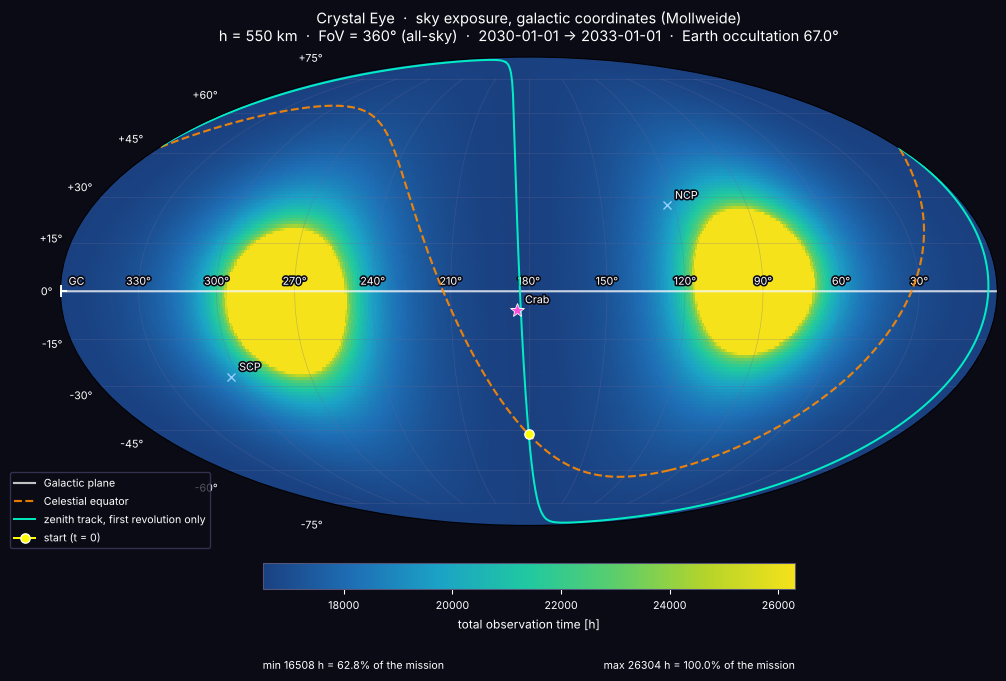

In [21]:
EXP_SHOW = EXP_CE        # <- EXP_CE, EXP_NUSES or EXP_ISS

CMAP_EXPOSURE = LinearSegmentedColormap.from_list("exposure", [
    "#1a4080", "#1e6eb5", "#1ba3c6", "#20c9a0", "#5dce6a", "#b5d42a", "#f5e21a"], N=512)


def mission_window(emap):
    '''Start and end of the time span covered by an exposure map.'''
    orb = emap["orbit"]
    return orb.epoch, orb.epoch + timedelta(days=emap["days"])


def mission_summary(emap):
    '''One line: dates, duration, revolutions, turns of the orbital plane.'''
    orb = emap["orbit"]
    start, end = mission_window(emap)
    revs  = emap["days"]*DAY/orb.period_s
    revs_txt = f"{int(round(revs, -2)):,}".replace(",", " ")
    head = (f"{orb.name}: {start:%Y-%m-%d} → {end:%Y-%m-%d}  ({emap['days']:.0f} days, "
            f"~{revs_txt} revolutions) · ")
    if not orb.use_j2:
        return head + "Keplerian orbit: the orbital plane does not move"
    turns = abs(orb.raan_dot_deg_day)*emap["days"]/360
    every = 360/abs(orb.raan_dot_deg_day)
    return head + f"orbital plane turned {turns:.1f} times by J2 (once every {every:.1f} d)"


def plot_exposure_map(emap, ax=None, figsize=(13, 7.2), units="hours", track=True,
                      title=None, cbar=True, fontsize=8, vmin=None, vmax=None):
    orb, grid = emap["orbit"], emap["grid"]
    start, end = mission_window(emap)
    data = emap["hours"] if units == "hours" else 100*emap["frac"]
    ax = sky_axes(ax, figsize=figsize, fontsize=fontsize, title=title or (
        f"{orb.name}  ·  sky exposure, galactic coordinates (Mollweide)\n"
        f"h = {orb.altitude_km:.0f} km  ·  "
        f"FoV = {fov_label(emap['fov_half_deg'])}  ·  {start:%Y-%m-%d} → {end:%Y-%m-%d}  ·  "
        f"Earth occultation {emap['rho']:.1f}°"))
    im = ax.pcolormesh(grid["xe"], grid["ye"], data, cmap=CMAP_EXPOSURE,
                       shading="flat", rasterized=True, zorder=1, linewidth=0,
                       antialiased=False,
                       vmin=data.min() if vmin is None else vmin,
                       vmax=data.max() if vmax is None else vmax)
    if track:
        zt = zenith_dirs(orb, time_grid(orb, 1.0, orb.period_s/400))
        plot_eci_curve(ax, zt, color="#00ffcc", lw=1.5, alpha=0.9, zorder=6,
                       label="zenith track, first revolution only")
        mark_eci(ax, zt[0], marker="o", color="yellow", ms=7, mec="w", zorder=11,
                 label="start (t = 0)")
    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05,
                                pad=0.07, shrink=0.8)
        cb.set_label("total observation time [h]" if units == "hours"
                     else "fraction of mission time [%]", color=SKY_TXT, fontsize=fontsize+1)
        cb.ax.tick_params(colors=SKY_TXT, labelsize=fontsize)
        cb.outline.set_edgecolor("#555577")
        h, f = emap["hours"], 100*emap["frac"]            # min / max, in hours and %
        for xa, ha, k in [(0.0, "left", np.argmin(f)), (1.0, "right", np.argmax(f))]:
            cb.ax.text(xa, -2.6, f"{'min' if xa == 0 else 'max'} {h.flat[k]:.0f} h = "
                       f"{f.flat[k]:.1f}% of the mission", transform=cb.ax.transAxes,
                       ha=ha, va="top", color=SKY_TXT, fontsize=fontsize)
    return ax, im


print(mission_summary(EXP_SHOW))
ax, _ = plot_exposure_map(EXP_SHOW)
ax.legend(loc="lower left", bbox_to_anchor=(-0.06, -0.06), fontsize=8, facecolor=SKY_BG,
          edgecolor="#444466", labelcolor=SKY_TXT, framealpha=0.7)
plt.savefig(OUTPUT / f"sky_exposure_galactic_{mission_tag(EXP_SHOW['orbit'])}_"
                     f"{EXP_SHOW['days']:.0f}d.png", dpi=150, facecolor=SKY_BG, bbox_inches="tight")
plt.show()

### 7.1 Why the map looks like this

On a Keplerian orbit the plane never moves, so the zenith runs along the **same great
circle** for the whole mission. What decides the exposure of a direction is then only its angle from the orbital plane, the beta angle of that direction, $\beta_{\rm src}$:

* Directions **on the orbital plane** ($\beta_{\rm src}=0$) are hidden the longest on every
  revolution: the minimum of the map (~63%), along a band that follows the zenith track.
* Moving away from the plane the hidden part of each revolution shrinks, exactly as the
  eclipse shrinks with $\beta_\odot$: hidden fraction $=\arccos(\cos\rho/\cos\beta_{\rm src})/\pi$.
* Directions with $|\beta_{\rm src}| > \rho \approx 67°$ — two **caps of radius ~23°
  around the poles of the orbit** — are **never** hidden: 100%.

Section 9 shows how J2, by turning the orbital plane, smears this pattern over the whole sky.

The three maps below compare the orbits, each over its whole mission, on a common
colour scale.

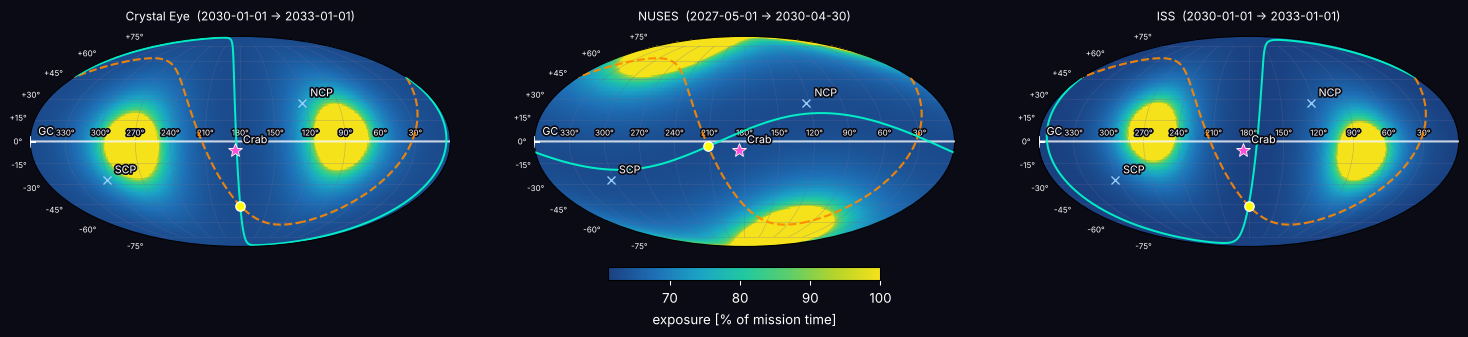

In [22]:
# the galactic maps of all orbits side by side, whole missions, on a common colour scale
EXP_ALL = [EXP_CE, EXP_NUSES, EXP_ISS]
fig, axes = plt.subplots(1, len(EXP_ALL), figsize=(6.4*len(EXP_ALL), 4.6), facecolor=SKY_BG,
                         subplot_kw={"projection": "mollweide"})
vmax = max(100*e["frac"].max() for e in EXP_ALL)
vmin = min(100*e["frac"].min() for e in EXP_ALL)
for emap, ax in zip(EXP_ALL, axes.ravel()):
    orb = emap["orbit"]
    start, end = mission_window(emap)
    _, im = plot_exposure_map(emap, ax=ax, units="percent", cbar=False,
                              fontsize=6, vmin=vmin, vmax=vmax, track=True,
                              title=f"{orb.name}  ({start:%Y-%m-%d} → {end:%Y-%m-%d})")
cb = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.04, pad=0.06, shrink=0.6)
cb.set_label("exposure [% of mission time]", color=SKY_TXT)
cb.ax.tick_params(colors=SKY_TXT)
plt.show()

### 7.2 Where the satellite spends its time, and how much of the view the Earth takes

For each band of latitude of the satellite: the hours spent over it during the whole
mission (number on top), split into the part of the field of view that is free and the part
covered by the Earth (grey). With a spherical Earth and a zenith-pointing detector the
Earth always fills the same fraction of the field of view, so the split is the same in
every band: what changes from band to band is the time. Try a smaller `FOV_DEG`: below
226° the Earth never enters the field of view.

mission                 days              FoV  Earth in FoV  hours lost
Crystal Eye             1096   360° (all-sky)         30.5%       8016 h
NUSES                   1095   360° (all-sky)         30.5%       8009 h
ISS                     1096   360° (all-sky)         32.7%       8601 h


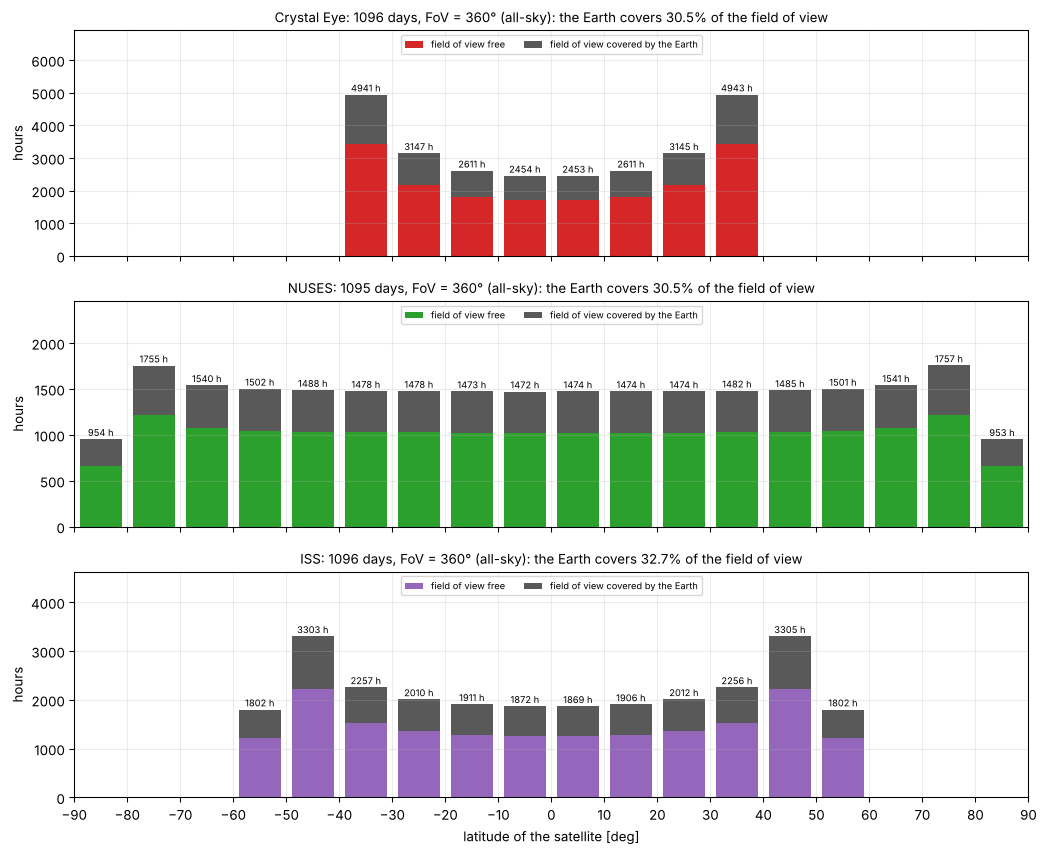

In [23]:
LAT_BIN = 10          # width of the latitude bands [deg]


def earth_fraction_of_fov(orb, fov_half_deg=None, h_atm_km=H_ATM_KM):
    '''Fraction of the field of view (solid angle) filled by the Earth disc.

    Zenith-pointing detector: FoV and Earth disc are concentric cones, so the Earth enters
    the FoV only if FoV/2 > 180 - rho, and then always fills the same fraction of it.
    '''
    half = np.radians(fov_half(orb) if fov_half_deg is None else fov_half_deg)
    edge = np.radians(180.0 - occultation_radius(orb, h_atm_km))   # Earth limb, from zenith
    if half <= edge:
        return 0.0
    return (np.cos(edge) - np.cos(half)) / (1.0 - np.cos(half))


edges = np.arange(-90, 90 + LAT_BIN, LAT_BIN)
cen   = 0.5*(edges[1:] + edges[:-1])
fig, axes = plt.subplots(len(ORBITS_K), 1, figsize=(11, 3*len(ORBITS_K)), sharex=True)
print(f"{'mission':22s} {'days':>5s}  {'FoV':>15s}  {'Earth in FoV':>12s}  {'hours lost':>10s}")
for ax, orb in zip(axes, ORBITS_K):
    n  = 40000
    dt = orb.duration_days*DAY/n
    t  = (np.arange(n) + 0.5)*dt
    hours = np.histogram(propagate(orb, t)["lat"], edges)[0]*dt/3600   # time over each band
    fe = earth_fraction_of_fov(orb)
    ax.bar(cen, hours*(1 - fe), width=0.8*LAT_BIN, color=orb.color, label="field of view free")
    ax.bar(cen, hours*fe, bottom=hours*(1 - fe), width=0.8*LAT_BIN, color="0.35",
           label="field of view covered by the Earth")
    for c, h in zip(cen, hours):
        if h > 0:
            ax.text(c, h + 0.02*hours.max(), f"{h:.0f} h", ha="center", fontsize=7)
    ax.set_ylim(0, 1.4*hours.max()); ax.set_ylabel("hours")
    ax.set_title(f"{orb.name}: {orb.duration_days:.0f} days, FoV = {fov_label(fov_half(orb))}: "
                 f"the Earth covers {100*fe:.1f}% of the field of view", fontsize=10)
    ax.legend(fontsize=7, loc="upper center", ncol=2)
    print(f"{orb.name:22s} {orb.duration_days:5.0f}  {fov_label(fov_half(orb)):>15s}  "
          f"{100*fe:11.1f}%  {hours.sum()*fe:9.0f} h")
axes[-1].set_xticks(edges); axes[-1].set_xlim(-90, 90)
axes[-1].set_xlabel("latitude of the satellite [deg]")
plt.tight_layout(); plt.show()

## 8. One source, seen from the satellite: the Crab Nebula

The exposure map answers *how much* of the sky we see; now we ask *when*. Fix a source, the Crab nebula, and follow it from the spacecraft, instant by instant (each instant labelled by its Julian date).

Seen from the satellite, the **Earth covers part of the sky**: once per revolution the Crab
goes behind the Earth disc and comes out again. We compute the instants of **entry** (the
source goes behind the Earth) and **exit** (it comes out from behind it), in Julian date and
UTC, and how long the source stays hidden. 

For a detector the **field of view** matters too (`FOV_DEG`, section 7). At each instant the
source is in one of three states: **in the field of view** (observed), **behind the Earth**,
or **above the horizon but outside the field of view** — the last one exists only when the
field of view is narrower than $2(180°-\rho) \approx 226°$.

`ORB_8` selects the mission and `TARGET` the source for the whole section. The tables
below cover the **first day** of the mission (the same on every day for a Keplerian orbit),
8.1 shows instants of that day and its first revolution, 8.2 the **whole mission**.


In [24]:
ORB_8  = CE_K                   # <- CE_K, NUSES_K or ISS_K: the mission used in this section
TARGET = "Crab Nebula"          # a key of SOURCES; for a new source add it to SOURCES (RA, Dec) [deg]


def intervals(mask, t_s, partial=False):
    '''Start/stop times [s] of every contiguous True run in `mask`.

    partial=False drops the runs cut by the start or the end of the time window (an
    occultation already going on at t_s[0], or not yet over at t_s[-1]).
    '''
    m  = np.concatenate([[False], np.asarray(mask, bool), [False]])
    d  = np.diff(m.astype(np.int8))
    i0, i1 = np.flatnonzero(d == 1), np.flatnonzero(d == -1) - 1
    if not partial:
        keep = (i0 > 0) & (i1 < len(t_s) - 1)
        i0, i1 = i0[keep], i1[keep]
    if len(i0) == 0:
        return np.empty((0, 2))
    step = t_s[1] - t_s[0]
    return np.column_stack([t_s[i0], t_s[i1] + step])


def jd_of(orb, t_s):
    '''Julian date of `t_s` seconds after the mission start.'''
    return julian_date(orb.epoch) + np.asarray(t_s)/DAY


def source_view(orb, ra_deg, dec_deg, t_s, fov_half_deg=None, h_atm_km=H_ATM_KM):
    '''Where a fixed source sits with respect to a zenith-pointing detector.'''
    fov_half_deg = fov_half(orb) if fov_half_deg is None else fov_half_deg
    k_hat = radec_to_unit(ra_deg, dec_deg)                   # direction of the source, k-hat
    r_hat = zenith_dirs(orb, t_s)                            # zenith r-hat
    theta = np.degrees(np.arccos(np.clip(r_hat @ k_hat, -1, 1)))  # theta = angle from the zenith
    rho = occultation_radius(orb, h_atm_km)
    occ = theta > 180.0 - rho                                # behind the Earth (limb)
    return dict(t_s=np.asarray(t_s, float), jd=jd_of(orb, t_s), zenith_angle=theta,
                occulted=occ, in_fov=(theta <= fov_half_deg) & ~occ, rho=rho)


def occultation_day(orb, day=0, target=TARGET, step_s=2.0):
    '''One day of the mission (day 0 = first day): states of the source and occultations.'''
    t   = day*DAY + np.arange(0.0, DAY, step_s)
    sv  = source_view(orb, *SOURCES[target], t)
    iv  = intervals(sv["occulted"], t)                   # full occultations only
    n_partial = len(intervals(sv["occulted"], t, partial=True)) - len(iv)
    entry_jd, exit_jd = jd_of(orb, iv[:, 0]), jd_of(orb, iv[:, 1])   # entry / exit [JD]
    duration_min = (iv[:, 1] - iv[:, 0])/60                          # time behind the Earth
    occ, inf = sv["occulted"].mean(), sv["in_fov"].mean()
    return dict(t=t, sv=sv, iv=iv, n_partial=n_partial, entry_jd=entry_jd, exit_jd=exit_jd,
                duration_min=duration_min, f_occ=occ, f_fov=inf, f_out=max(0.0, 1 - occ - inf))


def print_occultations(orb, rep, n_show=6):
    print(f"{'#':>3s}  {'entry JD':>16s}  {'entry UTC':>19s}  {'exit JD':>16s}  {'exit UTC':>8s}"
          f"  {'behind the Earth [min]':>22s}")
    for k in range(min(n_show, len(rep["iv"]))):
        a, b_ = rep["iv"][k]
        print(f"{k+1:3d}  {rep['entry_jd'][k]:16.6f}  "
              f"{(orb.epoch + timedelta(seconds=float(a))):%Y-%m-%d %H:%M:%S}  "
              f"{rep['exit_jd'][k]:16.6f}  {(orb.epoch + timedelta(seconds=float(b_))):%H:%M:%S}"
              f"  {rep['duration_min'][k]:22.2f}")
    print("  ...")


orb = ORB_8
rep = occultation_day(orb, day=0)
iv  = rep["iv"]                                      # used by the snapshots of 8.1

print(f"{TARGET} seen from {orb.name}, epoch JD {julian_date(orb.epoch):.5f}"
      f"  ({orb.epoch:%Y-%m-%d %H:%M} UTC), FoV = {fov_label(fov_half(orb))}")
print(f"first day: in the FoV {100*rep['f_fov']:.1f}% · behind the Earth {100*rep['f_occ']:.1f}% · "
      f"outside the FoV {100*rep['f_out']:.1f}%")
print(f"{len(iv)} full occultations (+{rep['n_partial']} cut by the start/end of the day), "
      f"mean length {rep['duration_min'].mean():.1f} min")
print("(Keplerian orbit: the same on every day of the mission; section 9 switches J2 on)\n")
print_occultations(orb, rep)

print(f"\nfirst day, all missions:")
for o in ORBITS_K:
    r = occultation_day(o, day=0)
    print(f"  {o.name:12s} FoV {fov_label(fov_half(o)):>14s}:  in the FoV {100*r['f_fov']:5.1f}%  "
          f"behind the Earth {100*r['f_occ']:5.1f}%  outside the FoV {100*r['f_out']:5.1f}%  |  "
          f"{len(r['iv']):2d} full occultations, mean {r['duration_min'].mean() if len(r['iv']) else 0:5.1f} min"
          f" (+{r['n_partial']} partial)")


Crab Nebula seen from Crystal Eye, epoch JD 2462502.50000  (2030-01-01 00:00 UTC), FoV = 360° (all-sky)
first day: in the FoV 62.9% · behind the Earth 37.1% · outside the FoV 0.0%
15 full occultations (+0 cut by the start/end of the day), mean length 35.6 min
(Keplerian orbit: the same on every day of the mission; section 9 switches J2 on)

  #          entry JD            entry UTC           exit JD  exit UTC  behind the Earth [min]
  1    2462502.528426  2030-01-01 00:40:56    2462502.553171  01:16:34                   35.63
  2    2462502.594861  2030-01-01 02:16:36    2462502.619583  02:52:12                   35.60
  3    2462502.661273  2030-01-01 03:52:14    2462502.686019  04:27:52                   35.63
  4    2462502.727708  2030-01-01 05:27:54    2462502.752431  06:03:30                   35.60
  5    2462502.794120  2030-01-01 07:03:32    2462502.818866  07:39:10                   35.63
  6    2462502.860556  2030-01-01 08:39:12    2462502.885278  09:14:48                 

### 8.1 The sky from the satellite at a given instant

The three maps below are instants of the **first day of the mission**, around the first
entry of the source behind the Earth: 12 minutes before, at the entry, 12 minutes after. The animation
that follows covers the first revolution, one frame every ~2 minutes.

The map shows **directions** seen from the satellite, on the galactic sky:

* **zenith**: straight above the satellite; the cyan line is the path it follows during
  the current revolution;
* **nadir**: towards the centre of the Earth, always opposite to the zenith;
* the **Earth** is the grey disc of radius $\rho$ around the nadir,
  $\sin\rho = (R_\oplus + h_{\rm atm})/a$ ($\rho \approx 67°$ at 550 km): every direction
  inside it is hidden;
* the **Sun** and the source do not move during a revolution: they are far away (parallax
  across the orbit ~0.003°) and the Sun moves only ~1° per day along the ecliptic.

The source turns red when the Earth disc passes over it. Pass any datetime or Julian date
to `sky_snapshot`.

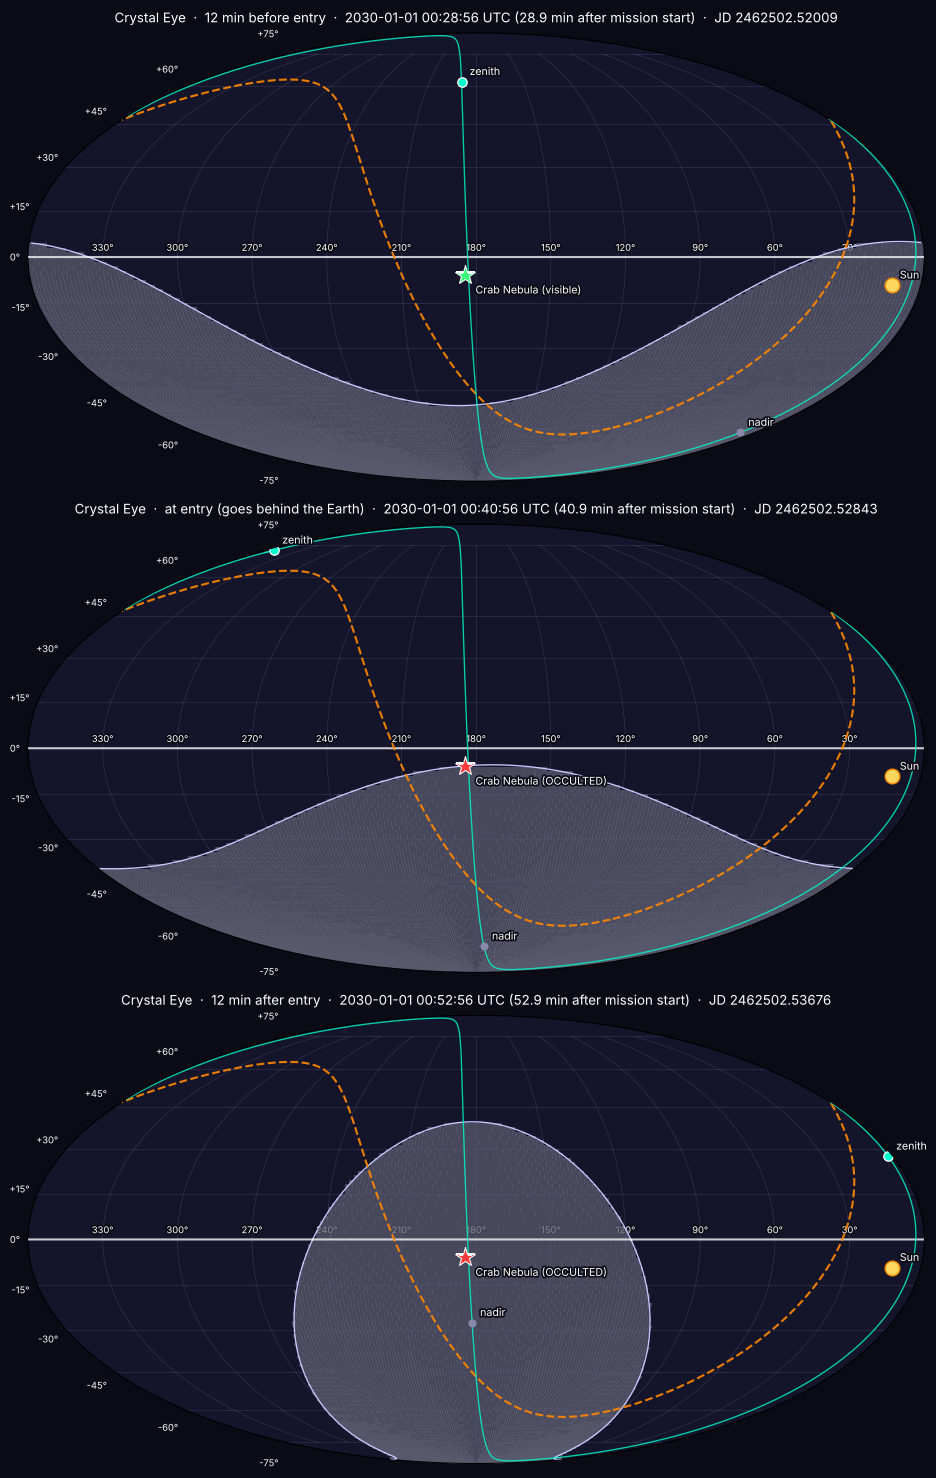

In [25]:
SNAP_GRID = make_sky_grid(240, 120)


def sky_snapshot(orb, when, target=TARGET, ax=None, fontsize=7, grid=None,
                 fov_half_deg=None, h_atm_km=H_ATM_KM, title=None):
    '''Galactic sky seen from `orb` at `when` (datetime or Julian date).'''
    fov_half_deg = fov_half(orb) if fov_half_deg is None else fov_half_deg
    grid = SNAP_GRID if grid is None else grid
    jd = when if not isinstance(when, datetime) else julian_date(when)
    t_s = (jd - julian_date(orb.epoch))*DAY
    r_hat = zenith_dirs(orb, t_s)[0]                         # zenith r-hat
    rho = occultation_radius(orb, h_atm_km)
    cosn = (grid["v_eci"] @ (-r_hat)).reshape(grid["shape"])          # cos(angle from nadir)

    ax = sky_axes(ax, fontsize=fontsize, landmarks=False)
    hidden = np.ma.masked_where(cosn < np.cos(np.radians(rho)), np.ones_like(cosn))
    ax.pcolormesh(grid["xe"], grid["ye"], hidden, cmap=mpl.colors.ListedColormap(["#5a5a6e"]),
                  alpha=0.75, shading="flat", zorder=2, rasterized=True,
                  linewidth=0, antialiased=False)
    ax.contour(grid["XC"], grid["YC"], cosn, levels=[np.cos(np.radians(rho))],
               colors="#c8c8ff", linewidths=1.0, zorder=3)
    if fov_half_deg < 180:
        ax.contour(grid["XC"], grid["YC"], -cosn, levels=[np.cos(np.radians(fov_half_deg))],
                   colors="orange", linewidths=1.2, zorder=3)

    trk = zenith_dirs(orb, t_s + time_grid(orb, 1.0, orb.period_s/300))
    plot_eci_curve(ax, trk, color="#00ffcc", lw=1.0, alpha=0.8, zorder=5)
    mark_eci(ax, r_hat, "zenith", marker="o", color="#00ffcc", ms=7, mec="w", zorder=11)
    mark_eci(ax, -r_hat, "nadir", marker="o", color="#8888aa", ms=5, zorder=11)
    sun = sun_unit_eci((jd - 2451545.0)/36525.0)
    mark_eci(ax, sun, "Sun", marker="o", color="#ffd75e", ms=11, mec="#ff8800", zorder=11)

    k_hat = radec_to_unit(*SOURCES[target])
    occ = np.degrees(np.arccos(np.clip(r_hat @ k_hat, -1, 1))) > 180 - rho
    mark_eci(ax, k_hat, f"{target} ({'OCCULTED' if occ else 'visible'})", offset=(8, -14), marker="*",
             color="#ff3b3b" if occ else "#39ff7a", ms=15, mec="w", mew=0.8, zorder=12)

    utc = datetime(2000, 1, 1, 12) + timedelta(days=jd - 2451545.0)
    ax.set_title(title or f"{orb.name}  ·  {utc:%Y-%m-%d %H:%M:%S} UTC  ·  "
                          f"{t_s/60:.1f} min after mission start  ·  JD {jd:.5f}",
                 color=SKY_TXT, fontsize=fontsize + 3, pad=10)
    return ax, occ


# three instants around the first occultation of the day: before, at the limb, behind
a0 = iv[0, 0]
fig, axes = plt.subplots(3, 1, figsize=(10, 15.5), facecolor=SKY_BG,
                         subplot_kw={"projection": "mollweide"})
for ax, dt_min, lbl in zip(axes, (-12.0, 0.0, +12.0),
                           ("12 min before entry", "at entry (goes behind the Earth)", "12 min after entry")):
    t_k = a0 + dt_min*60
    jd  = jd_of(orb, t_k)
    sky_snapshot(orb, jd, ax=ax)
    ax.set_title(f"{orb.name}  ·  {lbl}  ·  {(orb.epoch + timedelta(seconds=float(t_k))):%Y-%m-%d %H:%M:%S}"
                 f" UTC ({t_k/60:.1f} min after mission start)  ·  JD {jd:.5f}",
                 color=SKY_TXT, fontsize=10, pad=8)
plt.tight_layout(); plt.show()

In [26]:
MAKE_SKY_ANIMATION = True


def animate_sky(orb=None, frames=48, target=TARGET, dpi=70, fname=None):
    '''First revolution of the sky as seen from the spacecraft, galactic Mollweide.'''
    orb   = ORB_8 if orb is None else orb
    fname = fname or f"sky_view_{target.split()[0]}_{mission_tag(orb)}.gif"
    grid = make_sky_grid(180, 90)
    jd0  = julian_date(orb.epoch)
    jds  = jd0 + np.linspace(0, orb.period_s, frames, endpoint=False)/DAY
    fig = plt.figure(figsize=(8.5, 4.9), dpi=dpi, facecolor=SKY_BG)
    ax  = fig.add_subplot(111, projection="mollweide")

    def draw(k):
        ax.clear()
        sky_snapshot(orb, jds[k], target=target, ax=ax, grid=grid, fontsize=6)

    anim = FuncAnimation(fig, draw, frames=frames, interval=120)
    path = OUTPUT / fname
    anim.save(path, writer=PillowWriter(fps=8))
    plt.close(fig)
    print(f"animation written to {path}  ({path.stat().st_size/1e6:.1f} MB)")
    return path


if MAKE_SKY_ANIMATION:
    p = animate_sky()
    # "?v=..." forces the browser to reload the new GIF instead of a cached copy
    display(HTML(f'<img src="{p.as_posix()}?v={time.time():.0f}" width="{round(640*FIG_DPI/96)}">'))

animation written to output/sky_view_Crab_CE.gif  (1.3 MB)


### 8.2 How long the source is observed and hidden, over the whole mission

The same bars as in 7.2 (hours spent over each band of latitude of the satellite, whole mission) split this time into the hours in which the source is **in the field of view**,
**behind the Earth** and **above the horizon but outside the field of view**. A source north of the equator (the Crab is at Dec ≈ +22°)
is hidden more often while the satellite is in the southern hemisphere, when the Earth
stands between the two.

On the Keplerian orbit the source has the same geometry on every revolution, so its
fractions are the same for the whole mission; only their split between the latitude
bands changes.


Crab Nebula, whole mission
  Crystal Eye  in the FoV  62.8%  ( 16510 h)   behind the Earth  37.2%  (  9794 h)
  NUSES        in the FoV  63.0%  ( 16565 h)   behind the Earth  37.0%  (  9715 h)
  ISS          in the FoV  61.5%  ( 16168 h)   behind the Earth  38.5%  ( 10136 h)


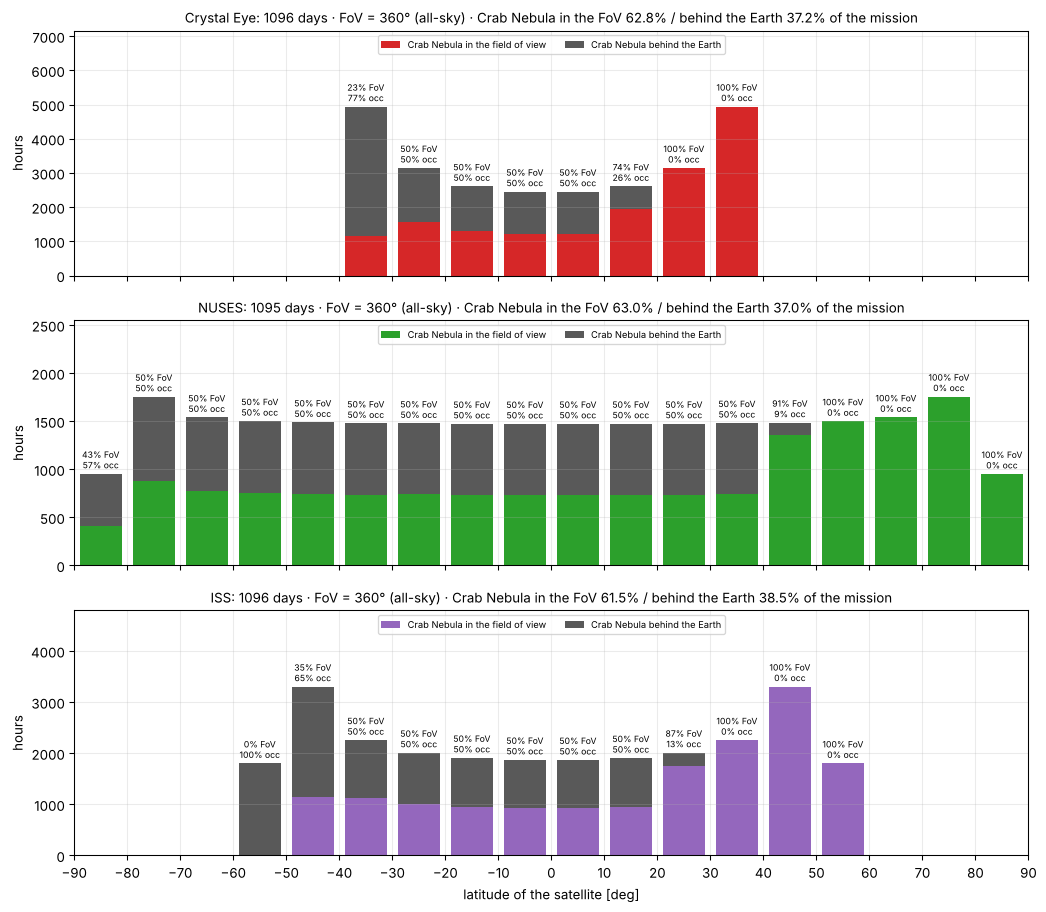

In [27]:
edges = np.arange(-90, 90 + LAT_BIN, LAT_BIN)          # same bands as in 7.2
cen   = 0.5*(edges[1:] + edges[:-1])


def plot_source_bars(orbits, label="", target=TARGET, n=40000):
    '''Hours per latitude band, whole mission: source in the FoV / behind the Earth / outside.'''
    fig, axes = plt.subplots(len(orbits), 1, figsize=(11, 3.2*len(orbits)), sharex=True)
    print(f"{target}, whole mission{label}")
    for ax, orb in zip(axes, orbits):
        dt = orb.duration_days*DAY/n
        t  = (np.arange(n) + 0.5)*dt
        lat = propagate(orb, t)["lat"]
        sv  = source_view(orb, *SOURCES[target], t)
        occ, inf = sv["occulted"], sv["in_fov"]
        out = ~occ & ~inf                                  # above the horizon, outside the FoV
        hours = np.histogram(lat, edges)[0]*dt/3600           # time over each band
        h_fov = np.histogram(lat[inf], edges)[0]*dt/3600      # ... source in the FoV
        h_occ = np.histogram(lat[occ], edges)[0]*dt/3600      # ... source behind the Earth
        h_out = np.maximum(hours - h_fov - h_occ, 0.0)        # ... source outside the FoV
        ax.bar(cen, h_fov, width=0.8*LAT_BIN, color=orb.color, label=f"{target} in the field of view")
        ax.bar(cen, h_occ, bottom=h_fov, width=0.8*LAT_BIN, color="0.35",
               label=f"{target} behind the Earth")
        if out.any():
            ax.bar(cen, h_out, bottom=h_fov + h_occ, width=0.8*LAT_BIN, color="0.75",
                   label=f"{target} outside the field of view")
        for c, h, f_, o_, u_ in zip(cen, hours, h_fov, h_occ, h_out):
            if h > 0:
                txt = f"{100*f_/h:.0f}% FoV\n{100*o_/h:.0f}% occ"
                if out.any():
                    txt += f"\n{100*u_/h:.0f}% out"
                ax.text(c, h + 0.02*hours.max(), txt, ha="center", va="bottom", fontsize=6.5)
        ax.set_ylim(0, (1.6 if out.any() else 1.45)*hours.max()); ax.set_ylabel("hours")
        tail = f" / outside the FoV {100*out.mean():.1f}%" if out.any() else ""
        ax.set_title(f"{orb.name}{label}: {orb.duration_days:.0f} days · FoV = {fov_label(fov_half(orb))} · "
                     f"{target} in the FoV {100*inf.mean():.1f}% / behind the Earth "
                     f"{100*occ.mean():.1f}%{tail} of the mission", fontsize=10)
        ax.legend(fontsize=7, loc="upper center", ncol=3)
        print(f"  {orb.name:12s} in the FoV {100*inf.mean():5.1f}%  ({h_fov.sum():6.0f} h)"
              f"   behind the Earth {100*occ.mean():5.1f}%  ({h_occ.sum():6.0f} h)"
              + (f"   outside the FoV {100*out.mean():5.1f}%  ({h_out.sum():6.0f} h)" if out.any() else ""))
    axes[-1].set_xticks(edges); axes[-1].set_xlim(-90, 90)
    axes[-1].set_xlabel("latitude of the satellite [deg]")
    plt.tight_layout(); plt.show()


plot_source_bars(ORBITS_K)


## 9. Switching J2 on: what changes in the sky

Sections 6–8 used **Keplerian** orbits: a fixed orbital plane, the same zenith circle on
every revolution and therefore the same geometry for a source — same entry, exit and
hidden time — for the whole mission. The real orbits of sections 1–5 are perturbed by
**J2**: the orbital plane precesses about the Earth's axis at $\dot\Omega$ (section 1),
once every $360°/|\dot\Omega|$ — about 60 days for Crystal Eye, one year for NUSES. Here we
switch J2 back on and compare the two cases, for the three missions.

For a source the cleanest way to see the consequence is its **beta angle** (section 5, with
the source in place of the Sun):

$$\sin\beta_{\rm src} = \hat{\mathbf k}\cdot\hat{\mathbf h}(t)$$

A source at infinity is hidden by the Earth exactly when the satellite is inside the
"shadow" the Earth would cast if that source were a lamp. So the hidden fraction of each
revolution is **the eclipse formula of section 5** with $\beta_{\rm src}$ in place of
$\beta_\odot$, and a source is **never occulted** while $|\beta_{\rm src}| > \rho$.

* Keplerian: $\hat{\mathbf h}$ is fixed $\Rightarrow$ $\beta_{\rm src}$ is constant;
* with J2: $\hat{\mathbf h}$ circles the celestial pole at a fixed angle $i$.

> J2 also changes the along-track rate (nodal period, section 1): that shifts the *timing*
> of entry and exit, while the nodal drift changes the *geometry*. Atmospheric drag and
> lunisolar perturbations are not modelled.

In [28]:
def with_j2(orb):
    '''Same mission with the J2 drifts, whatever USE_J2 was.'''
    return replace(orb, use_j2=True)


CE_J2, NUSES_J2, ISS_J2 = (with_j2(o) for o in ORBITS_K)
ORBITS_J2 = [CE_J2, NUSES_J2, ISS_J2]


def source_beta(orb, ra_deg, dec_deg, t_s):
    k_hat = radec_to_unit(ra_deg, dec_deg)
    return np.degrees(np.arcsin(np.clip(orbit_normal(orb, np.atleast_1d(t_s)) @ k_hat, -1, 1)))


def occultation_fraction(orb, beta_src_deg, h_atm_km=H_ATM_KM):
    '''Fraction of each revolution with the source behind the Earth (eclipse formula).'''
    c = np.cos(np.radians(occultation_radius(orb, h_atm_km))) / np.cos(np.radians(np.abs(beta_src_deg)))
    return np.where(np.abs(c) < 1.0, np.arccos(np.clip(c, -1, 1))/np.pi, 0.0)


# check: analytic fraction vs the numerical count, first revolution of each mission
for o in ORBITS_J2:
    tt  = np.arange(0.0, o.period_s, 1.0)
    num = source_view(o, *SOURCES[TARGET], tt)["occulted"].mean()
    ana = occultation_fraction(o, source_beta(o, *SOURCES[TARGET], 0.0))[0]
    print(f"{TARGET} hidden on the first revolution of {o.name:20s}: numerical {100*num:6.2f}%"
          f"   analytic {100*ana:6.2f}%")

print(f"\n{'mission':22s} {'dW/dt':>9s} {'plane turns':>12s} | {'beta_src, J2 (1 yr)':>20s} "
      f"{'Keplerian':>10s} | {'never-hidden days/yr':>21s}")
for oj, ok in zip(ORBITS_J2, ORBITS_K):
    days  = np.arange(0, 365.25, 0.25)
    bj    = source_beta(oj, *SOURCES[TARGET], days*DAY)
    bk    = source_beta(ok, *SOURCES[TARGET], 0.0)[0]
    nj    = (occultation_fraction(oj, bj) == 0).mean()*365.25
    nk    = 365.25 if occultation_fraction(ok, bk) == 0 else 0.0
    print(f"{oj.name:22s} {oj.raan_dot_deg_day:+8.3f}° {'every %5.1f d' % (360/abs(oj.raan_dot_deg_day)):>12s} | "
          f"{bj.min():+8.1f} .. {bj.max():+6.1f}°   {bk:+8.1f}° | J2 {nj:6.1f}   Kepler {nk:6.1f}")



Crab Nebula hidden on the first revolution of Crystal Eye         : numerical  37.26%   analytic  37.23%
Crab Nebula hidden on the first revolution of NUSES               : numerical  36.96%   analytic  36.97%
Crab Nebula hidden on the first revolution of ISS                 : numerical  38.55%   analytic  38.53%

mission                    dW/dt  plane turns |  beta_src, J2 (1 yr)  Keplerian |  never-hidden days/yr
Crystal Eye              -5.957° every  60.4 d |    -15.0 ..  +59.0°       -1.5° | J2    0.0   Kepler    0.0
NUSES                    +0.985° every 365.4 d |    -75.6 ..  +60.4°      +11.2° | J2   37.5   Kepler    0.0
ISS                      -4.947° every  72.8 d |    -29.6 ..  +73.7°      -11.0° | J2   28.2   Kepler    0.0


### How far J2 moves the orbit, day by day

Before looking at the sky, how big is the effect? J2 turns the orbital plane about the polar
axis at the rate $\dot\Omega$ of section 1: per revolution it is a fraction of a degree, per
day a few degrees, and after a few weeks the plane (and so the zenith) has turned by tens of degrees. A fixed source then sits at a different angle
$\beta_{\rm src}$ from the orbital plane, and its occultations change (9.3). Choose the day
with `DAY_9`; it is used again in 9.3.


In [29]:
DAY_9 = 30                       # <- day of the mission to analyse (0 = first day), used also in 9.3

print(f"{'mission':12s} {'per revolution':>15s} {'per day':>9s} | {'plane turned by day ' + str(DAY_9):>22s}"
      f" | {TARGET} beta_src: day 0 -> day {DAY_9}")
for o in ORBITS_J2:
    per_rev = np.degrees(o.raan_dot * o.period_s)        # node drift in one revolution [deg]
    per_day = np.degrees(o.raan_dot * DAY)               # node drift in one day [deg]
    total   = per_day * DAY_9                            # node drift accumulated by DAY_9 [deg]
    b0, b1  = source_beta(o, *SOURCES[TARGET], np.array([0.0, DAY_9 * DAY]))
    print(f"{o.name:12s} {per_rev:+14.3f}° {per_day:+8.3f}° | {total:+21.1f}°"
          f" | {b0:+6.1f}° -> {b1:+6.1f}°")


mission       per revolution   per day | plane turned by day 30 | Crab Nebula beta_src: day 0 -> day 30
Crystal Eye          -0.395°   -5.957° |                -178.7° |   -1.5° ->  +37.9°
NUSES                +0.066°   +0.985° |                 +29.6° |  +11.2° ->  +36.9°
ISS                  -0.319°   -4.947° |                -148.4° |  -11.0° ->  +16.5°


### 9.1 Where the detector points: Keplerian vs J2

Each dot is the **zenith direction** — where the detector points — at one instant of the
whole mission, coloured by the day. On the Keplerian orbit (left) all the dots, from the
first to the last day, fall on **the same circle**: the satellite looks at the same strip
of sky for the whole mission. With J2 (right) the orbital plane turns and the dots spread
over the whole band $|\delta| \le i$ ($180° - i$ for NUSES): the satellite looks at
different parts of the sky on different days, so the position of a fixed source with respect
to where the detector points changes in time. The exposure maps of 9.2 use the same
zenith directions, sampled much more densely: a direction is visible whenever the zenith
lies within $180° - \rho$ of it.

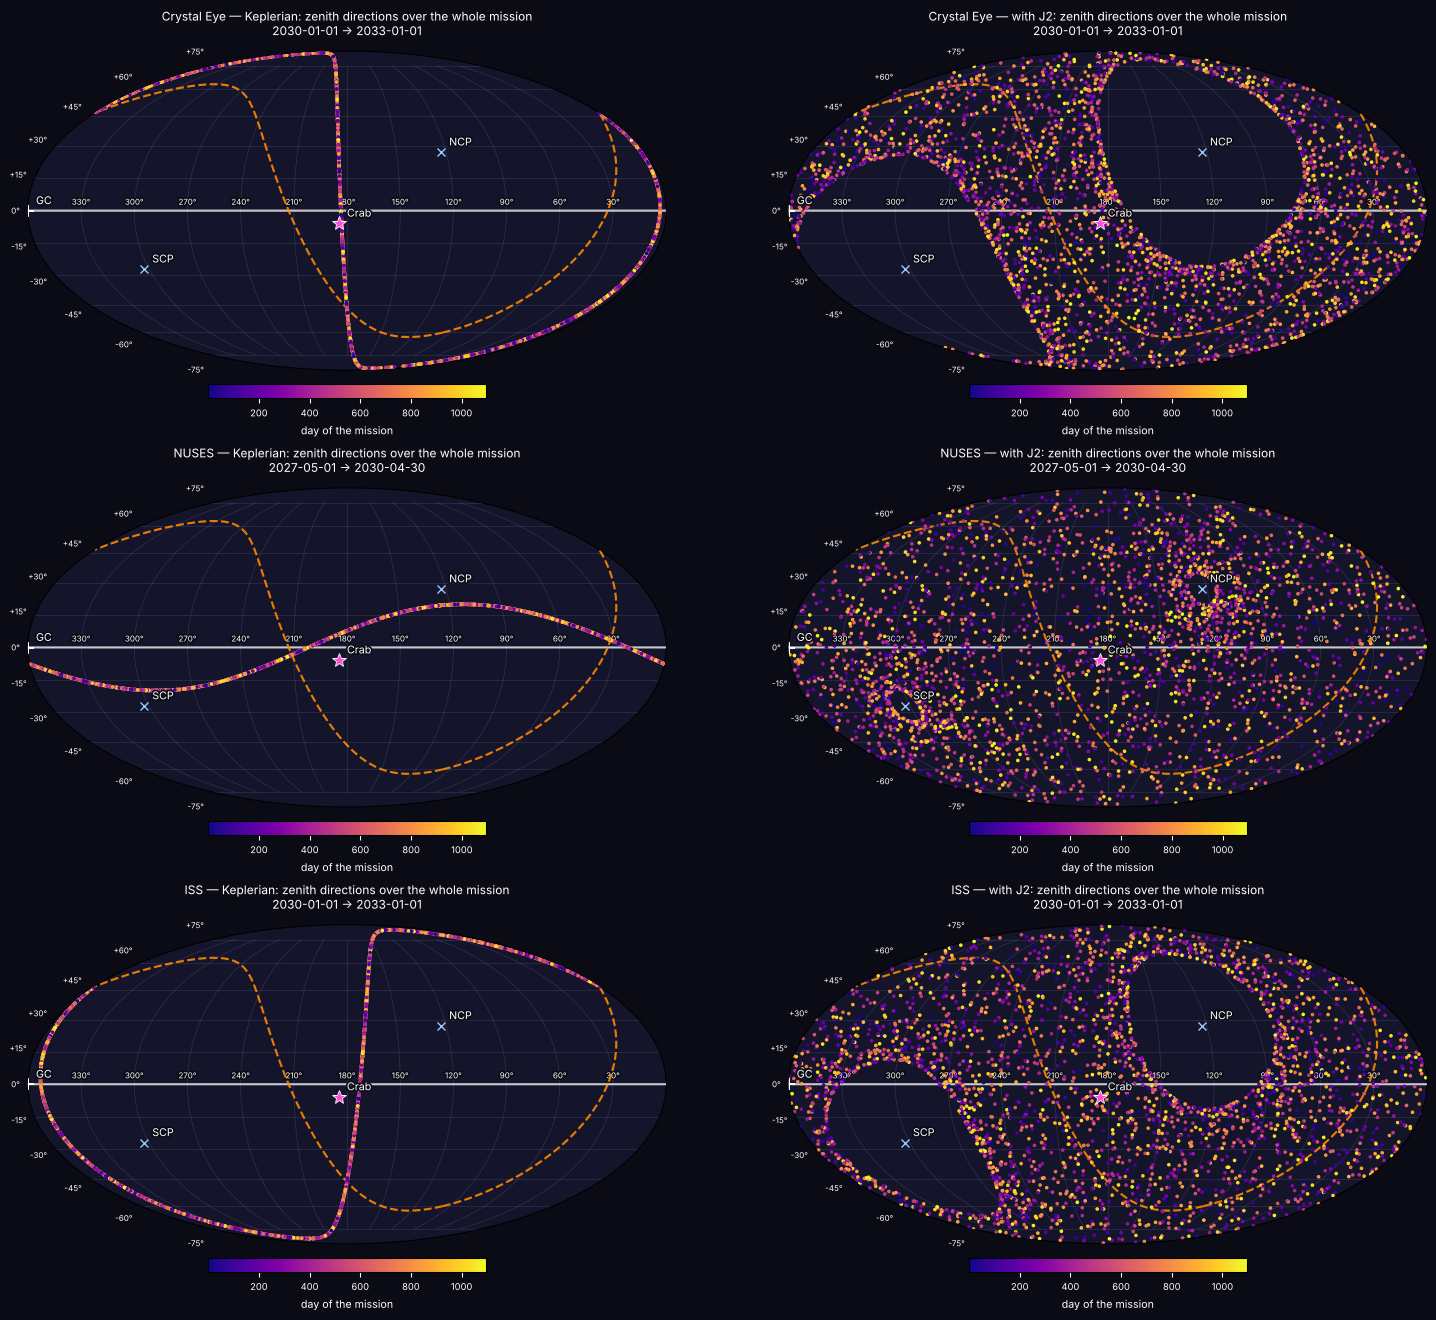

In [30]:
N_DOTS = 3000                                  # zenith directions per map
                                               # N_DOTS only sets how dense the picture is
rng    = np.random.default_rng(1)              # random instants: a regular step would alias
                                               # with the orbital period and draw fake patterns
fig, axes = plt.subplots(len(ORBITS_K), 2, figsize=(16, 4.6*len(ORBITS_K)), facecolor=SKY_BG,
                         subplot_kw={"projection": "mollweide"})
for row, (ok, oj) in enumerate(zip(ORBITS_K, ORBITS_J2)):
    for col, (o, lab) in enumerate([(ok, "Keplerian"), (oj, "with J2")]):
        ax = axes[row, col]
        start, end = o.epoch, o.end
        t = rng.uniform(0.0, o.duration_days*DAY, N_DOTS)   # over the whole mission, unsorted:
                                                             # early and late days mixed on top
        l, b = unit_to_lb(zenith_dirs(o, t))
        sky_axes(ax, fontsize=6, title=f"{o.name} — {lab}: zenith directions over the whole "
                                       f"mission\n{start:%Y-%m-%d} → {end:%Y-%m-%d}")
        sc = ax.scatter(lon_to_x(l), np.radians(b), c=t/DAY, cmap="plasma", s=3, zorder=5)
        cb = fig.colorbar(sc, ax=ax, orientation="horizontal", fraction=0.04, pad=0.04, shrink=0.6)
        cb.set_label("day of the mission", color=SKY_TXT, fontsize=8)
        cb.ax.tick_params(colors=SKY_TXT, labelsize=7)
plt.tight_layout(); plt.show()

### 9.2 Exposure maps: Keplerian vs J2

The same whole-mission maps of section 7, now with J2. Each
row has its own colour scale: note how much narrower the J2 range is. On the Keplerian orbit the exposure is
a band along the fixed orbital plane plus two never-hidden caps; with J2 the plane turns
many times during the mission (18 times for Crystal Eye in 3 years) and the pattern is
smeared over the whole sky:

* the exposure no longer depends on right ascension: it is a function of **declination
  only**, and the galactic map is that one-dimensional profile wrapped onto a tilted sphere;
* the zenith never strays more than $i$ from the celestial equator, so a pole is at most
  $90°+i$ away from it: if $90°+i < 180°-\rho$ — i.e. $i \lesssim 23°$ at 550 km — the
  celestial poles are never occulted;
* Crystal Eye, at $i = 37°$, is above that threshold: the north pole is hidden whenever the
  zenith dips below $\delta \approx -23°$, about a quarter of the time, and the maximum
  (~77%) sits on **rings around the celestial poles** at $|\delta| \approx 70°$;
* directions on the celestial equator are the most often hidden: they are visible ~64% of the
  time (the minimum of the map) and behind the Earth ~36%; the sun-synchronous NUSES has the opposite pattern, brightest on the
  equator and faintest on the poles.

No direction is 100% visible any more: J2 makes the sky coverage **more uniform**.

three whole-mission maps with J2 (CE 1096 d, NUSES 1095 d, ISS 1096 d) -- computing time 13.3 s



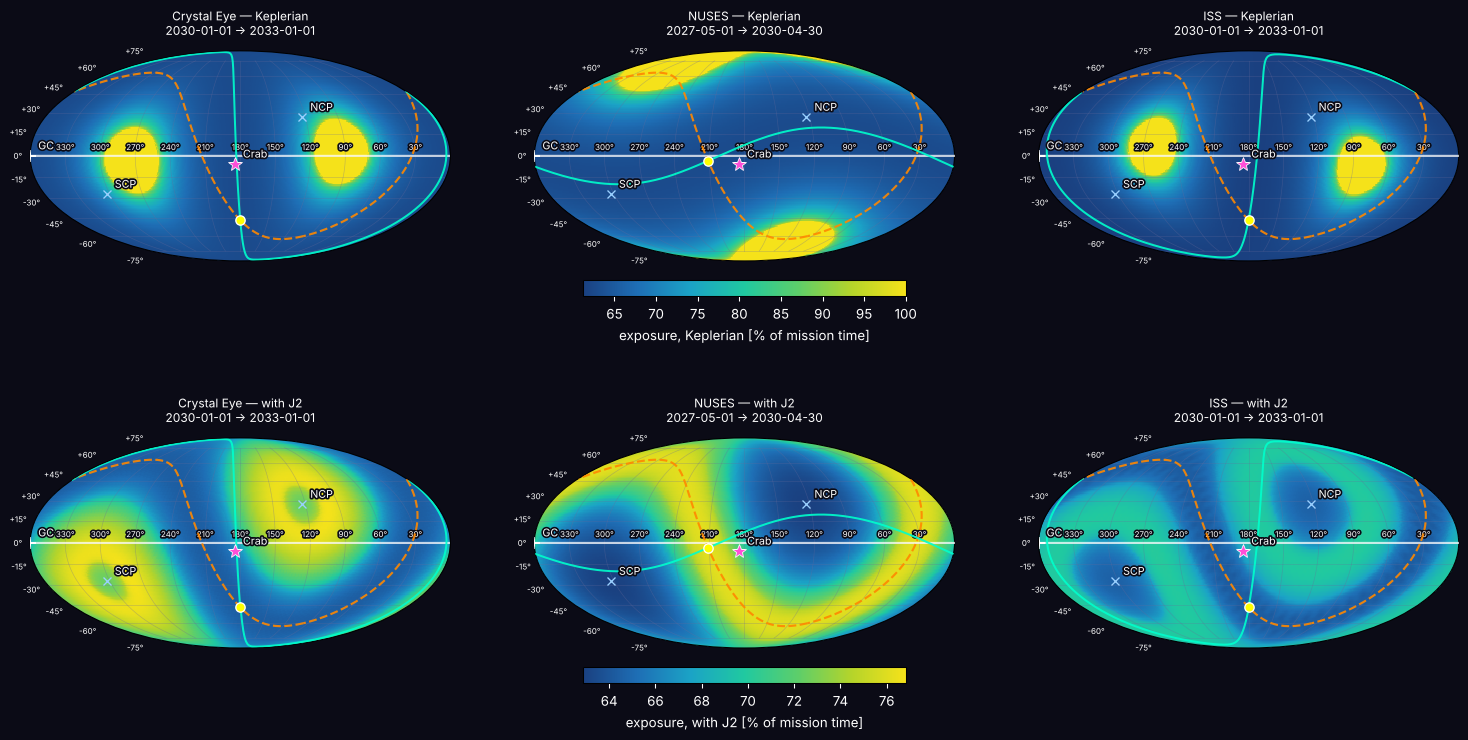

mission                |  Keplerian: min .. max  never-hidden sky |  with J2: min .. max  never-hidden sky | Crab Nebula hidden: Kepler -> J2
Crystal Eye            |   62.8 .. 100.0%     7.9% of the sky          |   64.3 ..  76.8%     0.0% of the sky   |  37.2% ->  33.9%
NUSES                  |   62.8 .. 100.0%     7.9% of the sky          |   62.9 ..  76.2%     0.0% of the sky   |  37.0% ->  28.2%
ISS                    |   61.2 .. 100.0%     6.2% of the sky          |   64.2 ..  70.1%     0.0% of the sky   |  38.5% ->  32.2%


In [31]:
_t0 = time.time()
EXP_CE_J2    = exposure_map(CE_J2,    GRID, n_samples=40000)
EXP_NUSES_J2 = exposure_map(NUSES_J2, GRID, n_samples=40000)
EXP_ISS_J2   = exposure_map(ISS_J2,   GRID, n_samples=40000)
print(f"three whole-mission maps with J2 ("
      + ", ".join(f"{mission_tag(o)} {o.duration_days:.0f} d" for o in ORBITS_J2)
      + f") -- computing time {time.time()-_t0:.1f} s\n")

PAIRS = [(EXP_CE, EXP_CE_J2), (EXP_NUSES, EXP_NUSES_J2), (EXP_ISS, EXP_ISS_J2)]
fig, axes = plt.subplots(2, 3, figsize=(19.2, 9.6), facecolor=SKY_BG,
                         subplot_kw={"projection": "mollweide"})
for row, lab in enumerate(["Keplerian", "with J2"]):          # one colour scale per row
    maps = [p[row] for p in PAIRS]
    vmin = min(100*e["frac"].min() for e in maps)
    vmax = max(100*e["frac"].max() for e in maps)
    for col, emap in enumerate(maps):
        orb = emap["orbit"]
        start, end = mission_window(emap)
        _, im = plot_exposure_map(emap, ax=axes[row, col], units="percent", cbar=False,
                                  fontsize=6, vmin=vmin, vmax=vmax, track=True,
                                  title=f"{orb.name} — {lab}\n{start:%Y-%m-%d} → {end:%Y-%m-%d}")
    cb = fig.colorbar(im, ax=list(axes[row]), orientation="horizontal", fraction=0.05,
                      pad=0.06, shrink=0.45)
    cb.set_label(f"exposure, {lab} [% of mission time]", color=SKY_TXT)
    cb.ax.tick_params(colors=SKY_TXT)
plt.show()

crab = radec_to_unit(*SOURCES[TARGET])
print(f"{'mission':22s} | {'Keplerian: min .. max  never-hidden sky':>40s} | "
      f"{'with J2: min .. max  never-hidden sky':>38s} | {TARGET} hidden: Kepler -> J2")
for (ek, ej) in PAIRS:
    hid = []
    for emap in (ek, ej):
        o  = emap["orbit"]
        t  = (np.arange(40000) + 0.5)*o.duration_days*DAY/40000
        hid.append(100*source_view(o, *SOURCES[TARGET], t)["occulted"].mean())
    w = np.cos(np.radians(GRID["b"]))                         # pixel solid angle ~ cos b
    nk, nj = [100*np.sum(w*(e["frac"] > 0.999))/np.sum(w) for e in (ek, ej)]
    print(f"{ek['orbit'].name:22s} | {100*ek['frac'].min():6.1f} .. {100*ek['frac'].max():5.1f}%"
          f"   {nk:5.1f}% of the sky          | {100*ej['frac'].min():6.1f} .. {100*ej['frac'].max():5.1f}%"
          f"   {nj:5.1f}% of the sky   | {hid[0]:5.1f}% -> {hid[1]:5.1f}%")

### 9.3 Entry and exit on a day of your choice, Keplerian vs J2

On the day `DAY_9` chosen above: J2 changes **when** the source goes behind the Earth (the
nodal period differs from the Keplerian one) and **for how long** (the source beta angle has
changed). Only full occultations are listed; the ones cut by the start or end of the day are
counted apart.


In [32]:
# DAY_9 is chosen above (section 9, 'How far J2 moves the orbit, day by day')

print(f"{TARGET}, day {DAY_9} of each mission, FoV from FOV_DEG: Keplerian vs J2\n")
print(f"{'mission':12s} {'model':>9s} | {'in FoV':>7s} {'behind':>7s} {'outside':>8s} | "
      f"{'full occ.':>9s} {'partial':>7s} {'mean [min]':>10s} | {'beta_src':>8s}")
for ok, oj in zip(ORBITS_K, ORBITS_J2):
    for o, lab in ((ok, "Keplerian"), (oj, "with J2")):
        r = occultation_day(o, day=DAY_9)
        b = source_beta(o, *SOURCES[TARGET], DAY_9*DAY)[0]
        print(f"{o.name:12s} {lab:>9s} | {100*r['f_fov']:6.1f}% {100*r['f_occ']:6.1f}% "
              f"{100*r['f_out']:7.1f}% | {len(r['iv']):9d} {r['n_partial']:7d} "
              f"{r['duration_min'].mean() if len(r['iv']) else 0:10.2f} | {b:+7.1f}°")

ORB_9 = with_j2(ORB_8)                          # the mission of section 8, with J2
rk, rj = occultation_day(ORB_8, day=DAY_9), occultation_day(ORB_9, day=DAY_9)
print(f"\n{ORB_9.name}, day {DAY_9}: the first occultations, Keplerian vs J2")
print(f"{'':3s}  {'---------- Keplerian ----------':>41s}   {'------------ with J2 ------------':>41s}")
print(f"{'#':>3s}  {'entry JD':>16s} {'exit JD':>16s} {'[min]':>7s}   {'entry JD':>16s} {'exit JD':>16s} {'[min]':>7s}")
for k in range(min(6, max(len(rk["iv"]), len(rj["iv"])))):
    cols = []
    for r in (rk, rj):
        cols.append(f"{r['entry_jd'][k]:16.6f} {r['exit_jd'][k]:16.6f} {r['duration_min'][k]:7.2f}"
                    if k < len(r["iv"]) else f"{'':41s}")
    print(f"{k+1:3d}  {cols[0]}   {cols[1]}")
print("  ...")


Crab Nebula, day 30 of each mission, FoV from FOV_DEG: Keplerian vs J2

mission          model |  in FoV  behind  outside | full occ. partial mean [min] | beta_src
Crystal Eye  Keplerian |   62.6%   37.4%     0.0% |        14       2      35.60 |    -1.5°
Crystal Eye    with J2 |   67.1%   32.9%     0.0% |        15       0      31.61 |   +37.9°
NUSES        Keplerian |   62.8%   37.2%     0.0% |        14       2      35.37 |   +11.2°
NUSES          with J2 |   66.4%   33.6%     0.0% |        15       0      32.26 |   +36.9°
ISS          Keplerian |   61.8%   38.2%     0.0% |        15       1      35.83 |   -11.0°
ISS            with J2 |   62.3%   37.7%     0.0% |        15       1      35.43 |   +16.5°

Crystal Eye, day 30: the first occultations, Keplerian vs J2
               ---------- Keplerian ----------           ------------ with J2 ------------
  #          entry JD          exit JD   [min]           entry JD          exit JD   [min]
  1    2462532.551875   2462532.576597  

### 9.4 How long the Crab is observed and hidden, with J2

The same bars as in 8.2 — hours over each band of latitude of the satellite, **whole
mission** — now with J2. Compare them with 8.2: on the Keplerian orbit the source keeps the
same geometry for the whole mission; with J2 it moves with respect to the orbital plane, the
time it stays hidden changes from week to week, and over the mission it is hidden less
(Crystal Eye: 37.2% → 33.9%).

The percentages on each bar are the share of the time spent **in that band of latitude**, not
of the whole mission. Above ~45° N the Crab (Dec +22°) can never be behind the Earth, so those
bands show 100% in the field of view, while over the whole mission NUSES sees it 71.8% of the
time.


Crab Nebula, whole mission (with J2)


  Crystal Eye  in the FoV  66.1%  ( 17387 h)   behind the Earth  33.9%  (  8917 h)
  NUSES        in the FoV  71.8%  ( 18881 h)   behind the Earth  28.2%  (  7399 h)


  ISS          in the FoV  67.8%  ( 17825 h)   behind the Earth  32.2%  (  8479 h)


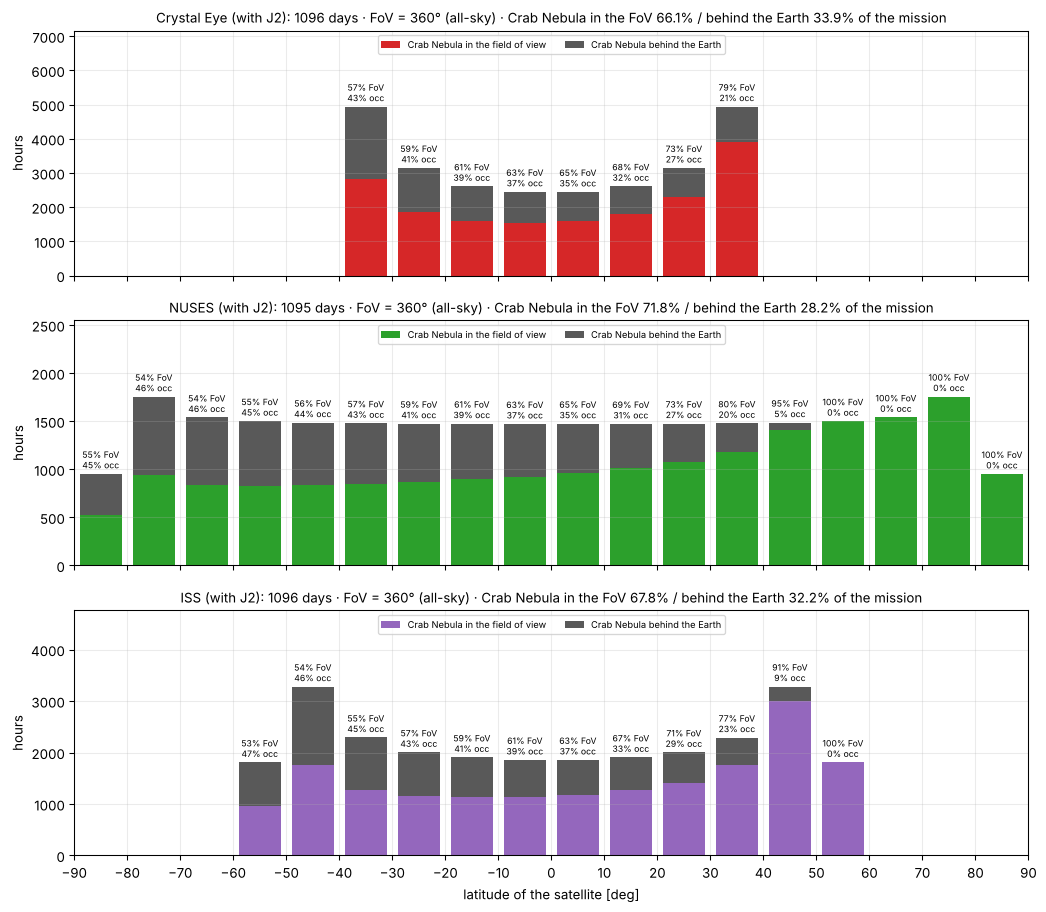

In [33]:
# the same bars as in 8.2 (same function, same bands), now on the orbits with J2
plot_source_bars(ORBITS_J2, label=" (with J2)")


---

## What to take away

* One chain of rotations — orbit → ECI → equatorial → galactic — turns the propagator into
  an instrument sky. Every map in sections 6–9 is that chain plus a dot product.
* On a **Keplerian** orbit the sky seen by a zenith-pointing all-sky instrument is frozen:
  a band along the orbital plane, hidden ~37% of the time, and two caps around the orbit
  poles that are never hidden. A source keeps the same visibility for the whole mission.
* **J2** turns the orbital plane (once every ~2 months for Crystal Eye, once a year for a
  sun-synchronous orbit): the long-term exposure becomes a function of declination only and
  much more uniform, and a source's visibility, governed by **its own beta angle** with the
  same formula as the solar eclipse, changes from week to week.